## <font color='red'>统计太阳能发电每天最大值和对应时刻？（项目实战）</font>

In [1]:
import pandas as pd
data = pd.read_csv('./太阳能发电/太阳能发电量分析.csv')
data

,时间,太阳能发电量
0,2021-01-01T00:00:00Z,0
1,2021-01-01T01:00:00Z,0
2,2021-01-01T02:00:00Z,0
3,2021-01-01T03:00:00Z,0
4,2021-01-01T04:00:00Z,0
...,...,...
8755,2021-12-31T19:00:00Z,29
8756,2021-12-31T20:00:00Z,29
8757,2021-12-31T21:00:00Z,29
8758,2021-12-31T22:00:00Z,29


In [2]:
data['时间'] = pd.to_datetime(data['时间'])
data['日期'] = data['时间'].dt.date
data['时分秒'] = data['时间'].dt.time
data

,时间,太阳能发电量,日期,时分秒
0,2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00
1,2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00
2,2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00
3,2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00
4,2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00
...,...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,2021-12-31,19:00:00
8756,2021-12-31 20:00:00+00:00,29,2021-12-31,20:00:00
8757,2021-12-31 21:00:00+00:00,29,2021-12-31,21:00:00
8758,2021-12-31 22:00:00+00:00,29,2021-12-31,22:00:00


In [3]:
def func(item):
    idx = item['太阳能发电量'].argmax()
    return item.iloc[idx]
result1 = data.groupby('日期').apply(func)
result1

,时间,太阳能发电量,日期,时分秒
日期,,,,
2021-01-01,2021-01-01 14:00:00+00:00,30,2021-01-01,14:00:00
2021-01-02,2021-01-02 15:00:00+00:00,44,2021-01-02,15:00:00
2021-01-03,2021-01-03 10:00:00+00:00,12,2021-01-03,10:00:00
2021-01-04,2021-01-04 11:00:00+00:00,7285,2021-01-04,11:00:00
2021-01-05,2021-01-05 17:00:00+00:00,15,2021-01-05,17:00:00
...,...,...,...,...
2021-12-27,2021-12-27 11:00:00+00:00,4260,2021-12-27,11:00:00
2021-12-28,2021-12-28 11:00:00+00:00,4598,2021-12-28,11:00:00
2021-12-29,2021-12-29 11:00:00+00:00,5283,2021-12-29,11:00:00


In [4]:
result1 = result1[['日期','时分秒','太阳能发电量']]
result1.columns = ['日期','最大时刻','最大值']
result1.to_csv('./太阳能发电/solar_result1.csv',index = False)
result1

,日期,最大时刻,最大值
日期,,,
2021-01-01,2021-01-01,14:00:00,30
2021-01-02,2021-01-02,15:00:00,44
2021-01-03,2021-01-03,10:00:00,12
2021-01-04,2021-01-04,11:00:00,7285
2021-01-05,2021-01-05,17:00:00,15
...,...,...,...
2021-12-27,2021-12-27,11:00:00,4260
2021-12-28,2021-12-28,11:00:00,4598
2021-12-29,2021-12-29,11:00:00,5283


## <font color='red'>统计每个季度太阳能发电量的算术平均值和方差？（项目实战）</font>

In [1]:
import pandas as pd
data = pd.read_csv('./太阳能发电/太阳能发电量分析.csv')
data['时间'] = pd.to_datetime(data['时间'])
data

,时间,太阳能发电量
0,2021-01-01 00:00:00+00:00,0
1,2021-01-01 01:00:00+00:00,0
2,2021-01-01 02:00:00+00:00,0
3,2021-01-01 03:00:00+00:00,0
4,2021-01-01 04:00:00+00:00,0
...,...,...
8755,2021-12-31 19:00:00+00:00,29
8756,2021-12-31 20:00:00+00:00,29
8757,2021-12-31 21:00:00+00:00,29
8758,2021-12-31 22:00:00+00:00,29


In [2]:
data.set_index('时间')

,太阳能发电量
时间,
2021-01-01 00:00:00+00:00,0
2021-01-01 01:00:00+00:00,0
2021-01-01 02:00:00+00:00,0
2021-01-01 03:00:00+00:00,0
2021-01-01 04:00:00+00:00,0
...,...
2021-12-31 19:00:00+00:00,29
2021-12-31 20:00:00+00:00,29
2021-12-31 21:00:00+00:00,29


In [3]:
result2 = data.set_index('时间').resample('Q').agg(['mean','var']).round(2)
result2

太阳能发电量             
                              mean          var
时间                                             
2021-03-31 00:00:00+00:00  1571.56   7650524.99
2021-06-30 00:00:00+00:00  2991.41  14180865.64
2021-09-30 00:00:00+00:00  2990.55  13774627.77
2021-12-31 00:00:00+00:00  1298.76   4179107.20

In [4]:
result2.index = ['第%s季度'%(i) for i in list('一二三四')]
result2.index.name = '季度'
result2.columns = ['算数平均值','方差']
result2.to_csv('./太阳能发电/solar_result2.csv',index = False)
result2

,算数平均值,方差
季度,,
第一季度,1571.56,7650524.99
第二季度,2991.41,14180865.64
第三季度,2990.55,13774627.77
第四季度,1298.76,4179107.20


## <font color='red'>统计每天截止当前时间点的累计太阳能发电量？（项目实战）</font>

<font color='green'>包括</font>当前时间点数据，例如:   

10点累计发电量，计算0点至10点的发电量总量；  

15点累计发电量，计算0点至15点的发电量总量；  

23点累计发电量，为当天发电量总量

In [5]:
import pandas as pd
data = pd.read_csv('./太阳能发电/太阳能发电量分析.csv')
data['时间'] = pd.to_datetime(data['时间'])
data['日期'] = data['时间'].dt.date
data

,时间,太阳能发电量,日期
0,2021-01-01 00:00:00+00:00,0,2021-01-01
1,2021-01-01 01:00:00+00:00,0,2021-01-01
2,2021-01-01 02:00:00+00:00,0,2021-01-01
3,2021-01-01 03:00:00+00:00,0,2021-01-01
4,2021-01-01 04:00:00+00:00,0,2021-01-01
...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,2021-12-31
8756,2021-12-31 20:00:00+00:00,29,2021-12-31
8757,2021-12-31 21:00:00+00:00,29,2021-12-31
8758,2021-12-31 22:00:00+00:00,29,2021-12-31


In [6]:
cumsum = data.groupby('日期')['太阳能发电量'].cumsum().to_frame('累计发电量')
cumsum

,累计发电量
0,0
1,0
2,0
3,0
4,0
...,...
8755,26814
8756,26843
8757,26872
8758,26901


In [7]:
cumsum.head(24)

,累计发电量
0,0
1,0
2,0
3,0
4,0
5,0
6,0
7,0
8,0
9,0


In [8]:
cumsum.tail(24)

,累计发电量
8736,0
8737,0
8738,0
8739,0
8740,0
8741,0
8742,36
8743,802
8744,3495
8745,7933


In [9]:
result3 = pd.concat([data[['时间','太阳能发电量']],cumsum],axis = 1)
result3

,时间,太阳能发电量,累计发电量
0,2021-01-01 00:00:00+00:00,0,0
1,2021-01-01 01:00:00+00:00,0,0
2,2021-01-01 02:00:00+00:00,0,0
3,2021-01-01 03:00:00+00:00,0,0
4,2021-01-01 04:00:00+00:00,0,0
...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,26814
8756,2021-12-31 20:00:00+00:00,29,26843
8757,2021-12-31 21:00:00+00:00,29,26872
8758,2021-12-31 22:00:00+00:00,29,26901


In [10]:
result3.to_csv('./太阳能发电/solar_result3.csv',index = False)
result3

,时间,太阳能发电量,累计发电量
0,2021-01-01 00:00:00+00:00,0,0
1,2021-01-01 01:00:00+00:00,0,0
2,2021-01-01 02:00:00+00:00,0,0
3,2021-01-01 03:00:00+00:00,0,0
4,2021-01-01 04:00:00+00:00,0,0
...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,26814
8756,2021-12-31 20:00:00+00:00,29,26843
8757,2021-12-31 21:00:00+00:00,29,26872
8758,2021-12-31 22:00:00+00:00,29,26901


## <font color='red'>统计每天太阳能发电量最多的时间段？（项目实战）</font>

<font color = 'green'>连续</font>的三个小时为一个时间段，例如：  

2点至5点发电量总量；  

3点至6点发电量总量；  

4点至7点发电量总量

### 方式一

In [1]:
import pandas as pd
data = pd.read_csv('./太阳能发电/太阳能发电量分析.csv')
data['时间'] = pd.to_datetime(data['时间'])
data['日期'] = data['时间'].dt.date
data['时分秒'] = data['时间'].dt.time
data

,时间,太阳能发电量,日期,时分秒
0,2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00
1,2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00
2,2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00
3,2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00
4,2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00
...,...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,2021-12-31,19:00:00
8756,2021-12-31 20:00:00+00:00,29,2021-12-31,20:00:00
8757,2021-12-31 21:00:00+00:00,29,2021-12-31,21:00:00
8758,2021-12-31 22:00:00+00:00,29,2021-12-31,22:00:00


In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
def func1(item):
    sub = item['太阳能发电量'] + item['太阳能发电量'].shift(1) + item['太阳能发电量'].shift(-1)
    sub = sub.to_frame('连续的三个小时发电量')
    return pd.concat([item,sub],axis = 1)
res = data.groupby('日期').apply(func1)
res

,时间,太阳能发电量,日期,时分秒,连续的三个小时发电量
0,2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00,NaN
1,2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00,0.0
2,2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00,0.0
3,2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00,0.0
4,2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00,0.0
...,...,...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,2021-12-31,19:00:00,87.0
8756,2021-12-31 20:00:00+00:00,29,2021-12-31,20:00:00,87.0
8757,2021-12-31 21:00:00+00:00,29,2021-12-31,21:00:00,87.0
8758,2021-12-31 22:00:00+00:00,29,2021-12-31,22:00:00,58.0


In [5]:
res.head(24)

,时间,太阳能发电量,日期,时分秒,连续的三个小时发电量
0,2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00,NaN
1,2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00,0.0
2,2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00,0.0
3,2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00,0.0
4,2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00,0.0
5,2021-01-01 05:00:00+00:00,0,2021-01-01,05:00:00,0.0
6,2021-01-01 06:00:00+00:00,0,2021-01-01,06:00:00,0.0
7,2021-01-01 07:00:00+00:00,0,2021-01-01,07:00:00,0.0
8,2021-01-01 08:00:00+00:00,0,2021-01-01,08:00:00,0.0
9,2021-01-01 09:00:00+00:00,0,2021-01-01,09:00:00,0.0


In [8]:
df = pd.DataFrame({'后移':data['太阳能发电量'].shift(1),
                   '前移':data['太阳能发电量'].shift(-1),
                   '当前':data['太阳能发电量']})
df

,后移,前移,当前
0,NaN,0.0,0
1,0.0,0.0,0
2,0.0,0.0,0
3,0.0,0.0,0
4,0.0,0.0,0
...,...,...,...
8755,29.0,29.0,29
8756,29.0,29.0,29
8757,29.0,29.0,29
8758,29.0,0.0,29


In [11]:
df.iloc[9:25]

,后移,前移,当前
9,0.0,0.0,0
10,0.0,0.0,0
11,0.0,10.0,0
12,0.0,20.0,10
13,10.0,30.0,20
14,20.0,0.0,30
15,30.0,0.0,0
16,0.0,0.0,0
17,0.0,0.0,0
18,0.0,0.0,0


In [12]:
def func2(item):
    idx = item['连续的三个小时发电量'].argmax()
    sub = pd.DataFrame({'时间':item['日期'].iloc[idx],
                         '连续3小时累计发电量':item['连续的三个小时发电量'].iloc[idx],
                         '开始时间':item['时分秒'].iloc[idx-1],
                         '结束时间':item['时分秒'].iloc[idx+1]},
                       index = [item['日期'].iloc[idx]])
    return sub
result4 = res.groupby('日期').apply(func2).reset_index(drop = True)
result4.to_csv('./太阳能发电/solar_result4.csv',index = False)
result4

,时间,连续3小时累计发电量,开始时间,结束时间
0,2021-01-01,60.0,12:00:00,14:00:00
1,2021-01-02,77.0,13:00:00,15:00:00
2,2021-01-03,31.0,10:00:00,12:00:00
3,2021-01-04,20978.0,10:00:00,12:00:00
4,2021-01-05,32.0,15:00:00,17:00:00
...,...,...,...,...
360,2021-12-27,12497.0,10:00:00,12:00:00
361,2021-12-28,12825.0,10:00:00,12:00:00
362,2021-12-29,15003.0,10:00:00,12:00:00
363,2021-12-30,11323.0,10:00:00,12:00:00


### 方式二

In [13]:
import pandas as pd
data = pd.read_csv('./太阳能发电/太阳能发电量分析.csv')
data['时间'] = pd.to_datetime(data['时间'],utc=True)
data

,时间,太阳能发电量
0,2021-01-01 00:00:00+00:00,0
1,2021-01-01 01:00:00+00:00,0
2,2021-01-01 02:00:00+00:00,0
3,2021-01-01 03:00:00+00:00,0
4,2021-01-01 04:00:00+00:00,0
...,...,...
8755,2021-12-31 19:00:00+00:00,29
8756,2021-12-31 20:00:00+00:00,29
8757,2021-12-31 21:00:00+00:00,29
8758,2021-12-31 22:00:00+00:00,29


In [14]:
data[['日期','时分秒']] = data['时间'].astype(str).str.split(' ',expand=True)
data

,时间,太阳能发电量,日期,时分秒
0,2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00+00:00
1,2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00+00:00
2,2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00+00:00
3,2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00+00:00
4,2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00+00:00
...,...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,2021-12-31,19:00:00+00:00
8756,2021-12-31 20:00:00+00:00,29,2021-12-31,20:00:00+00:00
8757,2021-12-31 21:00:00+00:00,29,2021-12-31,21:00:00+00:00
8758,2021-12-31 22:00:00+00:00,29,2021-12-31,22:00:00+00:00


In [15]:
data['时分秒'] = data['时分秒'].str.split('+').map(lambda x : x[0])
data

,时间,太阳能发电量,日期,时分秒
0,2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00
1,2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00
2,2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00
3,2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00
4,2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00
...,...,...,...,...
8755,2021-12-31 19:00:00+00:00,29,2021-12-31,19:00:00
8756,2021-12-31 20:00:00+00:00,29,2021-12-31,20:00:00
8757,2021-12-31 21:00:00+00:00,29,2021-12-31,21:00:00
8758,2021-12-31 22:00:00+00:00,29,2021-12-31,22:00:00


In [19]:
def func(item):
    display(item)
    item['累计发电量'] = item.rolling(3,min_periods=1)['太阳能发电量'].sum()
    display(item)
    item['开始时间'] = item['时分秒'].shift(2)
    display(item)
    res = item.sort_values('累计发电量').iloc[-1][['累计发电量','开始时间','时分秒']]
    display(res)
    return res
result = data.set_index('时间').iloc[:48].groupby('日期').apply(func)
result.columns = ['连续3小时累计发电量','开始时间','结束时间']
result.index.name = '时间'
result

,太阳能发电量,日期,时分秒
时间,,,
2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00
2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00
2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00
2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00
2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00
2021-01-01 05:00:00+00:00,0,2021-01-01,05:00:00
2021-01-01 06:00:00+00:00,0,2021-01-01,06:00:00
2021-01-01 07:00:00+00:00,0,2021-01-01,07:00:00
2021-01-01 08:00:00+00:00,0,2021-01-01,08:00:00


,太阳能发电量,日期,时分秒,累计发电量
时间,,,,
2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00,0.0
2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00,0.0
2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00,0.0
2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00,0.0
2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00,0.0
2021-01-01 05:00:00+00:00,0,2021-01-01,05:00:00,0.0
2021-01-01 06:00:00+00:00,0,2021-01-01,06:00:00,0.0
2021-01-01 07:00:00+00:00,0,2021-01-01,07:00:00,0.0
2021-01-01 08:00:00+00:00,0,2021-01-01,08:00:00,0.0


,太阳能发电量,日期,时分秒,累计发电量,开始时间
时间,,,,,
2021-01-01 00:00:00+00:00,0,2021-01-01,00:00:00,0.0,None
2021-01-01 01:00:00+00:00,0,2021-01-01,01:00:00,0.0,None
2021-01-01 02:00:00+00:00,0,2021-01-01,02:00:00,0.0,00:00:00
2021-01-01 03:00:00+00:00,0,2021-01-01,03:00:00,0.0,01:00:00
2021-01-01 04:00:00+00:00,0,2021-01-01,04:00:00,0.0,02:00:00
2021-01-01 05:00:00+00:00,0,2021-01-01,05:00:00,0.0,03:00:00
2021-01-01 06:00:00+00:00,0,2021-01-01,06:00:00,0.0,04:00:00
2021-01-01 07:00:00+00:00,0,2021-01-01,07:00:00,0.0,05:00:00
2021-01-01 08:00:00+00:00,0,2021-01-01,08:00:00,0.0,06:00:00


累计发电量        60.0
开始时间     12:00:00
时分秒      14:00:00
Name: 2021-01-01 14:00:00+00:00, dtype: object

,太阳能发电量,日期,时分秒
时间,,,
2021-01-02 00:00:00+00:00,0,2021-01-02,00:00:00
2021-01-02 01:00:00+00:00,0,2021-01-02,01:00:00
2021-01-02 02:00:00+00:00,0,2021-01-02,02:00:00
2021-01-02 03:00:00+00:00,0,2021-01-02,03:00:00
2021-01-02 04:00:00+00:00,0,2021-01-02,04:00:00
2021-01-02 05:00:00+00:00,0,2021-01-02,05:00:00
2021-01-02 06:00:00+00:00,0,2021-01-02,06:00:00
2021-01-02 07:00:00+00:00,0,2021-01-02,07:00:00
2021-01-02 08:00:00+00:00,0,2021-01-02,08:00:00


,太阳能发电量,日期,时分秒,累计发电量
时间,,,,
2021-01-02 00:00:00+00:00,0,2021-01-02,00:00:00,0.0
2021-01-02 01:00:00+00:00,0,2021-01-02,01:00:00,0.0
2021-01-02 02:00:00+00:00,0,2021-01-02,02:00:00,0.0
2021-01-02 03:00:00+00:00,0,2021-01-02,03:00:00,0.0
2021-01-02 04:00:00+00:00,0,2021-01-02,04:00:00,0.0
2021-01-02 05:00:00+00:00,0,2021-01-02,05:00:00,0.0
2021-01-02 06:00:00+00:00,0,2021-01-02,06:00:00,0.0
2021-01-02 07:00:00+00:00,0,2021-01-02,07:00:00,0.0
2021-01-02 08:00:00+00:00,0,2021-01-02,08:00:00,0.0


,太阳能发电量,日期,时分秒,累计发电量,开始时间
时间,,,,,
2021-01-02 00:00:00+00:00,0,2021-01-02,00:00:00,0.0,None
2021-01-02 01:00:00+00:00,0,2021-01-02,01:00:00,0.0,None
2021-01-02 02:00:00+00:00,0,2021-01-02,02:00:00,0.0,00:00:00
2021-01-02 03:00:00+00:00,0,2021-01-02,03:00:00,0.0,01:00:00
2021-01-02 04:00:00+00:00,0,2021-01-02,04:00:00,0.0,02:00:00
2021-01-02 05:00:00+00:00,0,2021-01-02,05:00:00,0.0,03:00:00
2021-01-02 06:00:00+00:00,0,2021-01-02,06:00:00,0.0,04:00:00
2021-01-02 07:00:00+00:00,0,2021-01-02,07:00:00,0.0,05:00:00
2021-01-02 08:00:00+00:00,0,2021-01-02,08:00:00,0.0,06:00:00


累计发电量        77.0
开始时间     13:00:00
时分秒      15:00:00
Name: 2021-01-02 15:00:00+00:00, dtype: object

,连续3小时累计发电量,开始时间,结束时间
时间,,,
2021-01-01,60.0,12:00:00,14:00:00
2021-01-02,77.0,13:00:00,15:00:00


In [17]:
result4['连续3小时累计发电量'].values == result['连续3小时累计发电量'].values

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [20]:
data['太阳能发电量']

0        0
1        0
2        0
3        0
4        0
        ..
8755    29
8756    29
8757    29
8758    29
8759     0
Name: 太阳能发电量, Length: 8760, dtype: int64

## <font color='red'>复杂数据比对？（项目实战）</font>

### 查看数据

In [81]:
import numpy as np
import pandas as pd
df_A = pd.read_csv('./A组.csv')
df_B = pd.read_csv('./B组.csv')
display(df_A.head(),df_B.head())

,指标一,指标二,指标三,核心指标,子指标
0,126,83,119,ACU,UNIT1
1,65,138,129,NaN,UNIT2
2,28,23,96,TCU,UNIT1
3,115,96,98,NaN,NaN
4,115,145,123,BCM,UNIT1


,指标一,指标二,指标三,核心指标,子指标
0,65,69,47,ACU,UNIT1
1,125,5,61,NaN,UNIT2
2,60,8,88,TCU,UNIT1
3,17,139,29,NaN,NaN
4,83,53,149,BCM,UNIT1


### 空数据删除

In [82]:
res1 = df_A.iloc[2:,3].dropna()
res2 = df_B.iloc[2:,3].dropna()
display(res1,res2)

2          TCU
4          BCM
7          HUW
9         PWSW
10         CCU
        ...   
287       OHCL
290    AFLS_FR
291    AFLS_FL
385        SYT
394       SKKS
Name: 核心指标, Length: 87, dtype: object

2          TCU
4          BCM
9         PWSW
10         CCU
14        MDPS
        ...   
291    AFLS_FL
372        WWJ
382        XMX
390      susss
396         DY
Name: 核心指标, Length: 92, dtype: object

### A、B非重核心指标去重

In [83]:
res1.unique()

array(['TCU', 'BCM', 'HUW', 'PWSW', 'CCU', 'MDPS', 'DAU', 'SPW', 'TES',
       'BDC', 'PDC', 'PTE', 'SSD', 'EEE', 'C_MDPS', 'UIP', 'LPL', 'PSI',
       'PSM', 'SBCM_DRV', 'SBCM_AST', 'SHU_FR', 'SHU_RR', 'PTGM', 'RCM',
       'ADAS_PRK', 'ADAS_DRV', 'DDM', 'UWB1', 'UWB3', 'UWB4', 'MLM',
       'ADM', 'RLDM', 'RRUU', 'DPSU', 'APSU', 'RRPSU', 'AFCU_DRV',
       'AFCU_AST', 'AFCU_RL', 'AFCU_RR', 'DPSS', 'APSS', 'RLPSS', 'RRPSS',
       'CCNC', 'MKBD', 'AMP', 'CLB', 'SLB', 'SLB1', 'SLB2', 'SLB3',
       'SLB4', 'POP', 'POP1', 'POP2', 'TPMS', 'TPMS1', 'SBCM_RR',
       'SBCM_RL', 'ILCU_RL', 'ILCU_RR', 'ILCU_FR', 'RR_RDR', 'RR_CMR',
       'FR_RDR', 'HSH', 'RFR', 'EQS', 'LKS', 'SDS', 'CLU', 'LBF1', 'LBF2',
       'LBF3', 'LBF4', 'LBF5', 'LBF6', 'LBF7', 'SSB', 'OHCL', 'AFLS_FR',
       'AFLS_FL', 'SYT', 'SKKS'], dtype=object)

In [84]:
# 集合知识点
s1 = set(res1) # A 就是 s1
s2 = set(res2) # B 就是 s2
print(s1,len(s1))
print(s2,len(s2))

{'SLB', 'RLPSS', 'SLB4', 'RLDM', 'SLB1', 'C_MDPS', 'ADAS_DRV', 'MKBD', 'APSS', 'PTE', 'POP', 'BDC', 'DAU', 'SSD', 'CLB', 'AFCU_AST', 'OHCL', 'PTGM', 'PSM', 'LBF3', 'AFCU_DRV', 'CLU', 'SBCM_RR', 'AFLS_FR', 'RR_RDR', 'LKS', 'EEE', 'LBF2', 'UWB3', 'TPMS', 'LBF1', 'ILCU_FR', 'TES', 'LBF4', 'LPL', 'FR_RDR', 'ADM', 'RR_CMR', 'PWSW', 'RCM', 'BCM', 'SLB3', 'DPSU', 'LBF5', 'EQS', 'APSU', 'LBF7', 'SYT', 'POP2', 'POP1', 'SKKS', 'HSH', 'UWB4', 'UIP', 'SDS', 'SLB2', 'RRUU', 'CCNC', 'SBCM_AST', 'UWB1', 'RRPSU', 'HUW', 'PDC', 'SPW', 'TCU', 'LBF6', 'AFLS_FL', 'MLM', 'AFCU_RR', 'TPMS1', 'ILCU_RL', 'MDPS', 'ADAS_PRK', 'RFR', 'DDM', 'SBCM_DRV', 'AFCU_RL', 'PSI', 'SHU_FR', 'RRPSS', 'SSB', 'ILCU_RR', 'SBCM_RL', 'SHU_RR', 'AMP', 'CCU', 'DPSS'} 87
{'SLB', 'RRDM', 'RLPSS', 'SLB4', 'RLDM', 'SLB1', 'C_MDPS', 'ADAS_DRV', 'MKBD', 'APSS', 'DY', 'PTE', 'POP', 'BDC', 'DAU', 'SSD', 'CLB', 'AFCU_AST', 'OHCL', 'PTGM', 'PSM', 'LBF3', 'AFCU_DRV', 'UWB2', 'XMX', 'CLU', 'SBCM_RR', 'AFLS_FR', 'RR_RDR', 'LKS', 'EEE', 'CCNF',

### A与B核心指标差异

In [85]:
# A中有B中没有
res3 = s1.difference(s2)
print(res3,len(res3))
# B中有的A没有
res4 = s2.difference(s1)
print(res4,len(res4))

{'RRUU', 'SKKS', 'PSI', 'HUW', 'SYT'} 5
{'CCNF', 'susss', 'RRDM', 'SHVU_FR', 'DY', 'RLPSU', 'UWB2', 'XMX', 'PSD', 'WWJ'} 10


### A与B共同核心指标

In [86]:
# A和B共同指标，交集
res5 = s1.intersection(s2)
print(res5,len(res5))

{'SLB', 'RLPSS', 'SLB4', 'SLB1', 'RLDM', 'C_MDPS', 'ADAS_DRV', 'MKBD', 'APSS', 'PTE', 'POP', 'BDC', 'DAU', 'SSD', 'CLB', 'AFCU_AST', 'OHCL', 'PTGM', 'PSM', 'LBF3', 'AFCU_DRV', 'CLU', 'SBCM_RR', 'AFLS_FR', 'RR_RDR', 'LKS', 'EEE', 'LBF2', 'UWB3', 'TPMS', 'LBF1', 'ILCU_FR', 'TES', 'LBF4', 'LPL', 'FR_RDR', 'ADM', 'RR_CMR', 'PWSW', 'RCM', 'BCM', 'SLB3', 'DPSU', 'LBF5', 'EQS', 'APSU', 'LBF7', 'POP2', 'POP1', 'HSH', 'UWB4', 'UIP', 'SDS', 'SLB2', 'CCNC', 'SBCM_AST', 'UWB1', 'RRPSU', 'PDC', 'SPW', 'TCU', 'LBF6', 'AFLS_FL', 'MLM', 'AFCU_RR', 'TPMS1', 'ILCU_RL', 'MDPS', 'ADAS_PRK', 'RFR', 'DDM', 'SBCM_DRV', 'AFCU_RL', 'SHU_FR', 'RRPSS', 'SSB', 'ILCU_RR', 'SBCM_RL', 'SHU_RR', 'AMP', 'CCU', 'DPSS'} 82


### 指标个数统计

In [87]:
length = res1.size
res1 = [length] + list(res1.values) # A中非重核心指标

length = res2.size
res2 = [length] + list(res2.values) # B中非重核心指标

length = len(res3)
res3 = [length] + list(res3) # A中有B中没有

length = len(res4)
res4 = [length] + list(res4) # B中有A中没有

length = len(res5)
res5 = [length] + list(res5) # A和B中都有的元素，交集

print(res3)

[5, 'RRUU', 'SKKS', 'PSI', 'HUW', 'SYT']


### 长度补齐

In [88]:
# 数据合并，将其变为DataFrame
# 数据长度，不一致，所以报错
result = pd.DataFrame({'A组非重核心指标':res1,'B组非重核心指标':res2,
                       'A组比B组多的指标':res3,'B组比A组多的指标':res4,
                       'A组合和B组共同指标':res5})
result

ValueError: All arrays must be of the same length

In [89]:
# 数据长度补齐
len_max = max([len(res1),len(res2),len(res3),len(res4),len(res5)])

# 将每一个列表，进行长度的补齐，使用空数据，进行补齐
def func(res):
    length = len(res) # 当前长度
    if len_max > length:
        res = res + [np.nan]* (len_max - length)
    return res
res1 = func(res1)
res2 = func(res2)
res3 = func(res3)
res4 = func(res4)
res5 = func(res5)

# 构建DataFrame，并保存
result = pd.DataFrame({'A组非重核心指标':res1,'B组非重核心指标':res2,
                       'A组比B组多的指标':res3,'B组比A组多的指标':res4,
                       'A组合和B组共同指标':res5})

display(result.head(10))
result.to_csv('./数据比对结果.csv',index = False)

,A组非重核心指标,B组非重核心指标,A组比B组多的指标,B组比A组多的指标,A组合和B组共同指标
0,87,92,5,10,82
1,TCU,TCU,RRUU,CCNF,SLB
2,BCM,BCM,SKKS,susss,RLPSS
3,HUW,PWSW,PSI,RRDM,SLB4
4,PWSW,CCU,HUW,SHVU_FR,SLB1
5,CCU,MDPS,SYT,DY,RLDM
6,MDPS,DAU,NaN,RLPSU,C_MDPS
7,DAU,SPW,NaN,UWB2,ADAS_DRV
8,SPW,TES,NaN,XMX,MKBD
9,TES,BDC,NaN,PSD,APSS


##  <font color='red'>企业用电数据处理？（项目实战）</font>

### 数据加载

In [1]:
import numpy as np
import pandas as pd
data = pd.read_csv('./企业用电分析.csv')
display(data.head())
display(data.isna().sum()) # 空数据查看

,编号ID,用电行业,202101,202102,202103,202104,202105,202106,202107,202108,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
0,9070193615X,教育业,32368.00,11033.5,24240.5,19264.00,27067.50,37000.00,41242.0,36206.00,...,23037.00,19821.5,24667.5,30476.50,33664.5,25223.00,25637.00,17911.0,21431.0,26634.0
1,9070193716X,教育业,16912.15,5099.9,8476.6,7891.55,10684.75,10865.45,12260.8,11967.05,...,11489.05,19503.2,13901.8,16184.15,13613.5,120.35,3661.45,1107.2,2183.5,1200.2
2,9070097519X,教育业,9787.00,3084.2,7049.5,5979.50,7480.60,8102.00,9044.5,7773.50,...,6444.10,5536.4,10039.9,12989.60,15400.0,7249.40,5846.80,3983.3,4877.2,4805.6
3,9070001396X,教育业,50340.40,21189.8,19862.5,15824.60,14024.20,18382.70,18401.2,19712.60,...,16299.70,15522.8,25503.1,31519.40,41034.1,28385.30,30186.40,22013.0,27431.8,36815.9
4,9070000995X,教育业,41042.00,18113.0,18090.5,14991.50,14742.50,16019.50,16500.5,16868.00,...,19382.80,21897.8,35271.4,51678.80,54080.2,39678.80,37289.80,23679.2,30920.8,44693.0


编号ID      0
用电行业      0
202101    0
202102    0
202103    0
202104    0
202105    1
202106    2
202107    2
202108    8
202109    7
202110    8
202111    6
202112    4
202201    6
202202    9
202203    2
202204    7
202205    2
202206    3
202207    1
202208    0
202209    0
202210    0
202211    0
202212    0
202301    0
202302    0
202303    0
202304    0
202305    0
202306    0
dtype: int64

In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11932 entries, 0 to 11931
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   编号ID    11932 non-null  object 
 1   用电行业    11932 non-null  object 
 2   202101  11932 non-null  float64
 3   202102  11932 non-null  float64
 4   202103  11932 non-null  float64
 5   202104  11932 non-null  float64
 6   202105  11931 non-null  float64
 7   202106  11930 non-null  float64
 8   202107  11930 non-null  float64
 9   202108  11924 non-null  float64
 10  202109  11925 non-null  float64
 11  202110  11924 non-null  float64
 12  202111  11926 non-null  float64
 13  202112  11928 non-null  float64
 14  202201  11926 non-null  float64
 15  202202  11923 non-null  float64
 16  202203  11930 non-null  float64
 17  202204  11925 non-null  float64
 18  202205  11930 non-null  float64
 19  202206  11929 non-null  float64
 20  202207  11931 non-null  float64
 21  202208  11932 non-null  float64
 22

### 数据处理

In [7]:
cols = data.columns[2:] # 用电月份
# 数据转换函数
def func(item): # 这里的item是DataFrame
#     display(item)
    m = item.median(axis = 1) # Series,中位数
    upper_limit = item.quantile(0.95,axis = 1) # Series
    lower_limit = item.quantile(0.05,axis = 1) # Series
#     display('-----',m,upper_limit,lower_limit) # 查看数据
    c1 = item > upper_limit.values[0] # 大于95%条件，DataFrame
    c2 = item < lower_limit.values[0] # 小于5%条件，DataFrame
#     display('*****',c1)
#     display('+++++',c1.T.sum(),c2.T.sum()) # 查看数据
    cond = c1.T | c2.T # 条件或运算，这里的cond是一个DataFrame
#     display('*****',cond,cond.sum()) # 查看数据
    item_T = item.T # 行变列，转置
#     display(item_T)
    item_T[cond.iloc[:,0]] = m
#     display(item_T) # 查看数据
    item = item_T.T # 上面操作结束，异常值，处理了
#     display(item)
    # 同时针对缺失值进行处理，利用前后各一个非空值的算术平均值进行填充
    item = (item.bfill(axis = 1) + item.ffill(axis = 1))/2
    return item # 数据返回


result = data.groupby('编号ID')[cols].apply(func) # apply函数，那么传递给func的item是DataFrame
display('=====',result)
result.sort_index(level=-1,inplace=True)
result.reset_index(drop = True,inplace = True) # 将索引删除

result = pd.concat([data.iloc[:,:2],result],axis = 1)
result.to_csv('./企业用电数据处理(答案).csv',index = False)
result

'====='

,,202101,202102,202103,202104,202105,202106,202107,202108,202109,202110,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
编号ID,,,,,,,,,,,,,,,,,,,,,,
9070000007X,3531,3249.150,3922.400,4032.55,2060.60,2901.25,3126.20,4347.40,3683.00,3508.75,2110.10,...,2653.60,2058.950,3968.65,2886.50,4574.800,3409.10,3372.100,3249.150,2730.25,3044.15
9070000390X,890,8743.275,8743.275,11950.00,11992.00,8144.00,8870.55,10408.00,10416.00,9734.00,7652.00,...,8248.00,8032.000,9956.00,12856.00,8743.275,8616.00,9436.000,5576.000,7938.00,7488.00
9070000803X,892,8182.600,2347.850,6343.00,4013.45,5000.05,5637.80,6704.95,5021.75,6715.15,3132.20,...,3715.30,5270.225,6639.10,7579.40,5270.225,5342.00,4898.200,5270.225,2783.20,3258.95
9070000897X,891,4536.000,3524.000,3390.00,2192.00,3672.00,3666.00,4954.00,3974.00,3938.00,2350.00,...,4336.00,2330.000,3218.00,2474.00,3300.000,3524.00,3278.000,2220.000,3546.00,3502.00
9070000995X,4,41042.000,18113.000,18090.50,14991.50,14742.50,16019.50,16500.50,16868.00,19492.80,22117.60,...,19382.80,21897.800,35271.40,22117.60,22117.600,39678.80,37289.800,23679.200,30920.80,44693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9799979387X,10537,3660.100,3140.000,3660.10,4350.20,5032.60,3510.80,4603.60,3245.00,4378.60,3839.60,...,3472.60,2996.600,3663.40,3406.40,4717.000,2426.00,3656.800,2165.600,3143.20,3660.10
9799986954X,5307,1028.520,17779.255,6061.43,6922.12,5196.74,3226.59,8029.17,3481.59,6391.95,7677.07,...,18878.21,26369.430,12180.33,22876.03,17152.590,18329.62,17779.255,24343.660,24926.10,20667.93
9799990997X,10374,3069.750,2200.680,2958.97,3069.75,2874.57,2296.19,3248.13,2266.03,2810.98,1932.47,...,3538.01,3090.770,5531.50,5816.01,3069.750,4937.96,5884.370,2982.170,3683.90,3048.73


,编号ID,用电行业,202101,202102,202103,202104,202105,202106,202107,202108,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
0,9070193615X,教育业,32368.00,26135.500,24240.500,19264.000,27067.50,37000.00,26135.50,36206.000,...,23037.00,19821.500,24667.50,30476.50,33664.500,25223.00,25637.000,17911.000,21431.00,26634.00
1,9070193716X,教育业,16912.15,5099.900,8476.600,7891.550,10684.75,10865.45,12260.80,11967.050,...,11489.05,11291.050,13901.80,16184.15,13613.500,11291.05,3661.450,11291.050,2183.50,1200.20
2,9070097519X,教育业,9787.00,7262.600,7049.500,5979.500,7480.60,8102.00,9044.50,7773.500,...,6444.10,5536.400,10039.90,12989.60,7262.600,7249.40,5846.800,7262.600,4877.20,4805.60
3,9070001396X,教育业,21013.05,21189.800,19862.500,15824.600,14024.20,18382.70,18401.20,19712.600,...,16299.70,15522.800,25503.10,31519.40,21013.050,28385.30,30186.400,22013.000,27431.80,36815.90
4,9070000995X,教育业,41042.00,18113.000,18090.500,14991.500,14742.50,16019.50,16500.50,16868.000,...,19382.80,21897.800,35271.40,22117.60,22117.600,39678.80,37289.800,23679.200,30920.80,44693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11927,9078537750X,供暖业,1420.15,1190.325,1190.325,437.300,1409.80,463.25,1344.85,1190.325,...,1411.00,430.400,1552.60,464.90,1514.800,462.20,1533.400,453.950,1415.65,449.90
11928,9366410119X,供暖业,2442.58,1148.560,1806.150,327.820,1463.54,361.62,1341.68,324.410,...,1285.71,619.820,2382.53,2139.78,1313.695,2225.29,1313.695,917.170,1499.11,397.76
11929,9549405189X,供暖业,1752.00,752.000,1876.740,842.000,1808.00,761.00,1510.50,845.000,...,1758.00,732.000,1824.00,701.00,1765.000,1510.50,1704.000,697.000,1711.00,706.00
11930,9598997006X,供暖业,1304.48,287.110,1327.910,1268.045,1274.44,292.77,1824.15,504.760,...,1452.04,825.310,1368.00,279.09,1349.100,282.35,1308.140,1268.045,1364.27,351.12


In [8]:
data

,编号ID,用电行业,202101,202102,202103,202104,202105,202106,202107,202108,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
0,9070193615X,教育业,32368.00,11033.50,24240.50,19264.00,27067.50,37000.00,41242.00,36206.00,...,23037.00,19821.50,24667.50,30476.50,33664.50,25223.00,25637.00,17911.00,21431.00,26634.00
1,9070193716X,教育业,16912.15,5099.90,8476.60,7891.55,10684.75,10865.45,12260.80,11967.05,...,11489.05,19503.20,13901.80,16184.15,13613.50,120.35,3661.45,1107.20,2183.50,1200.20
2,9070097519X,教育业,9787.00,3084.20,7049.50,5979.50,7480.60,8102.00,9044.50,7773.50,...,6444.10,5536.40,10039.90,12989.60,15400.00,7249.40,5846.80,3983.30,4877.20,4805.60
3,9070001396X,教育业,50340.40,21189.80,19862.50,15824.60,14024.20,18382.70,18401.20,19712.60,...,16299.70,15522.80,25503.10,31519.40,41034.10,28385.30,30186.40,22013.00,27431.80,36815.90
4,9070000995X,教育业,41042.00,18113.00,18090.50,14991.50,14742.50,16019.50,16500.50,16868.00,...,19382.80,21897.80,35271.40,51678.80,54080.20,39678.80,37289.80,23679.20,30920.80,44693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11927,9078537750X,供暖业,1420.15,364.40,1713.85,437.30,1409.80,463.25,1344.85,383.75,...,1411.00,430.40,1552.60,464.90,1514.80,462.20,1533.40,453.95,1415.65,449.90
11928,9366410119X,供暖业,2442.58,1148.56,1806.15,327.82,1463.54,361.62,1341.68,324.41,...,1285.71,619.82,2382.53,2139.78,3560.68,2225.29,3063.16,917.17,1499.11,397.76
11929,9549405189X,供暖业,1752.00,752.00,1876.74,842.00,1808.00,761.00,1896.00,845.00,...,1758.00,732.00,1824.00,701.00,1765.00,609.00,1704.00,697.00,1711.00,706.00
11930,9598997006X,供暖业,1304.48,287.11,1327.91,259.73,1274.44,292.77,1824.15,504.76,...,1452.04,825.31,1368.00,279.09,1349.10,282.35,1308.14,4650.19,1364.27,351.12


## <font color='red'>用电企业繁荣指数与衰退指数统计？（项目实战）</font>

统计不同行业2022年9月份的繁荣指数和衰退指数  

* 繁荣指数=月度用电量超过去年同期的企业数量/该行业总用户数量$*$100%   



* 衰退指数=月度用电量小于去年同期用电量20%的小微企业数量/行业用户数量$*$100%）  

计算结果保留2位小数，并按照超产率降序排序。

In [9]:
import numpy as np
import pandas as pd
data = pd.read_csv('企业用电数据处理(答案).csv')
data

,编号ID,用电行业,202101,202102,202103,202104,202105,202106,202107,202108,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
0,9070193615X,教育业,32368.00,26135.500,24240.500,19264.000,27067.50,37000.00,26135.50,36206.000,...,23037.00,19821.500,24667.50,30476.50,33664.500,25223.00,25637.000,17911.000,21431.00,26634.00
1,9070193716X,教育业,16912.15,5099.900,8476.600,7891.550,10684.75,10865.45,12260.80,11967.050,...,11489.05,11291.050,13901.80,16184.15,13613.500,11291.05,3661.450,11291.050,2183.50,1200.20
2,9070097519X,教育业,9787.00,7262.600,7049.500,5979.500,7480.60,8102.00,9044.50,7773.500,...,6444.10,5536.400,10039.90,12989.60,7262.600,7249.40,5846.800,7262.600,4877.20,4805.60
3,9070001396X,教育业,21013.05,21189.800,19862.500,15824.600,14024.20,18382.70,18401.20,19712.600,...,16299.70,15522.800,25503.10,31519.40,21013.050,28385.30,30186.400,22013.000,27431.80,36815.90
4,9070000995X,教育业,41042.00,18113.000,18090.500,14991.500,14742.50,16019.50,16500.50,16868.000,...,19382.80,21897.800,35271.40,22117.60,22117.600,39678.80,37289.800,23679.200,30920.80,44693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11927,9078537750X,供暖业,1420.15,1190.325,1190.325,437.300,1409.80,463.25,1344.85,1190.325,...,1411.00,430.400,1552.60,464.90,1514.800,462.20,1533.400,453.950,1415.65,449.90
11928,9366410119X,供暖业,2442.58,1148.560,1806.150,327.820,1463.54,361.62,1341.68,324.410,...,1285.71,619.820,2382.53,2139.78,1313.695,2225.29,1313.695,917.170,1499.11,397.76
11929,9549405189X,供暖业,1752.00,752.000,1876.740,842.000,1808.00,761.00,1510.50,845.000,...,1758.00,732.000,1824.00,701.00,1765.000,1510.50,1704.000,697.000,1711.00,706.00
11930,9598997006X,供暖业,1304.48,287.110,1327.910,1268.045,1274.44,292.77,1824.15,504.760,...,1452.04,825.310,1368.00,279.09,1349.100,282.35,1308.140,1268.045,1364.27,351.12


In [10]:
def func(item): # item 是DataFrame
    return pd.Series([sum(item['202209'] > item['202109'])*100/item.shape[0],
                      sum(item['202209'] < item['202109']*0.2)*100/item.shape[0]],
                     index=['繁荣指数（%）', '衰退指数（%）'])
result = data.groupby('用电行业').apply(func).round(2)
display(result)
result.sort_values(by = '繁荣指数（%）',ascending=False,inplace=True)
result.to_csv('./企业用电繁荣与衰退指数统计(答案).csv',index = False)
result

,繁荣指数（%）,衰退指数（%）
用电行业,,
IT行业,37.14,0.00
人工智能,55.88,0.00
供暖业,49.12,0.44
制冷业,50.00,0.00
卫生服务业,46.85,0.43
娱乐业,47.95,0.35
批发零售,47.06,0.00
教育业,45.91,1.50
煤矿业,44.76,0.23


,繁荣指数（%）,衰退指数（%）
用电行业,,
第一产业,60.00,0.00
人工智能,55.88,0.00
制冷业,50.00,0.00
供暖业,49.12,0.44
娱乐业,47.95,0.35
批发零售,47.06,0.00
卫生服务业,46.85,0.43
物流业,46.15,0.40
教育业,45.91,1.50


## <font color='red'>企业用电量连续三个月累计汇总？（项目实战）</font>

统计每个用户的 <font color='red'>t-2</font> 至 <font color = 'red'>t</font> 时段的总用电量 

* t表示当前时刻

* 如:2022年12月统计的窗口为2022年10月至2022年12月, 2023年6月统计的窗口为2023年4月至2023年6月 

* 空数据填充规则：
   * 起始月使用原数据填充;
   * 第二个月空数据使用前两个月用电量之和填充；

In [11]:
import pandas as pd
data = pd.read_csv('./企业用电数据处理(答案).csv')
data

,编号ID,用电行业,202101,202102,202103,202104,202105,202106,202107,202108,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
0,9070193615X,教育业,32368.00,26135.500,24240.500,19264.000,27067.50,37000.00,26135.50,36206.000,...,23037.00,19821.500,24667.50,30476.50,33664.500,25223.00,25637.000,17911.000,21431.00,26634.00
1,9070193716X,教育业,16912.15,5099.900,8476.600,7891.550,10684.75,10865.45,12260.80,11967.050,...,11489.05,11291.050,13901.80,16184.15,13613.500,11291.05,3661.450,11291.050,2183.50,1200.20
2,9070097519X,教育业,9787.00,7262.600,7049.500,5979.500,7480.60,8102.00,9044.50,7773.500,...,6444.10,5536.400,10039.90,12989.60,7262.600,7249.40,5846.800,7262.600,4877.20,4805.60
3,9070001396X,教育业,21013.05,21189.800,19862.500,15824.600,14024.20,18382.70,18401.20,19712.600,...,16299.70,15522.800,25503.10,31519.40,21013.050,28385.30,30186.400,22013.000,27431.80,36815.90
4,9070000995X,教育业,41042.00,18113.000,18090.500,14991.500,14742.50,16019.50,16500.50,16868.000,...,19382.80,21897.800,35271.40,22117.60,22117.600,39678.80,37289.800,23679.200,30920.80,44693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11927,9078537750X,供暖业,1420.15,1190.325,1190.325,437.300,1409.80,463.25,1344.85,1190.325,...,1411.00,430.400,1552.60,464.90,1514.800,462.20,1533.400,453.950,1415.65,449.90
11928,9366410119X,供暖业,2442.58,1148.560,1806.150,327.820,1463.54,361.62,1341.68,324.410,...,1285.71,619.820,2382.53,2139.78,1313.695,2225.29,1313.695,917.170,1499.11,397.76
11929,9549405189X,供暖业,1752.00,752.000,1876.740,842.000,1808.00,761.00,1510.50,845.000,...,1758.00,732.000,1824.00,701.00,1765.000,1510.50,1704.000,697.000,1711.00,706.00
11930,9598997006X,供暖业,1304.48,287.110,1327.910,1268.045,1274.44,292.77,1824.15,504.760,...,1452.04,825.310,1368.00,279.09,1349.100,282.35,1308.140,1268.045,1364.27,351.12


In [12]:
data.set_index('编号ID',inplace=True)
display(data)

,用电行业,202101,202102,202103,202104,202105,202106,202107,202108,202109,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
编号ID,,,,,,,,,,,,,,,,,,,,,
9070193615X,教育业,32368.00,26135.500,24240.500,19264.000,27067.50,37000.00,26135.50,36206.000,27144.500,...,23037.00,19821.500,24667.50,30476.50,33664.500,25223.00,25637.000,17911.000,21431.00,26634.00
9070193716X,教育业,16912.15,5099.900,8476.600,7891.550,10684.75,10865.45,12260.80,11967.050,10534.150,...,11489.05,11291.050,13901.80,16184.15,13613.500,11291.05,3661.450,11291.050,2183.50,1200.20
9070097519X,教育业,9787.00,7262.600,7049.500,5979.500,7480.60,8102.00,9044.50,7773.500,7262.600,...,6444.10,5536.400,10039.90,12989.60,7262.600,7249.40,5846.800,7262.600,4877.20,4805.60
9070001396X,教育业,21013.05,21189.800,19862.500,15824.600,14024.20,18382.70,18401.20,19712.600,15606.400,...,16299.70,15522.800,25503.10,31519.40,21013.050,28385.30,30186.400,22013.000,27431.80,36815.90
9070000995X,教育业,41042.00,18113.000,18090.500,14991.500,14742.50,16019.50,16500.50,16868.000,19492.800,...,19382.80,21897.800,35271.40,22117.60,22117.600,39678.80,37289.800,23679.200,30920.80,44693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9078537750X,供暖业,1420.15,1190.325,1190.325,437.300,1409.80,463.25,1344.85,1190.325,1190.325,...,1411.00,430.400,1552.60,464.90,1514.800,462.20,1533.400,453.950,1415.65,449.90
9366410119X,供暖业,2442.58,1148.560,1806.150,327.820,1463.54,361.62,1341.68,324.410,1258.490,...,1285.71,619.820,2382.53,2139.78,1313.695,2225.29,1313.695,917.170,1499.11,397.76
9549405189X,供暖业,1752.00,752.000,1876.740,842.000,1808.00,761.00,1510.50,845.000,1848.000,...,1758.00,732.000,1824.00,701.00,1765.000,1510.50,1704.000,697.000,1711.00,706.00


In [13]:
data.iloc[:,1:].T

编号ID,9070193615X,9070193716X,9070097519X,9070001396X,9070000995X,9070007134X,9070008890X,9070039089X,9070031687X,9074159380X,...,9747087346X,9077999894X,9077991113X,9077991171X,9078919184X,9078537750X,9366410119X,9549405189X,9598997006X,9737794947X
202101,32368.0,16912.15,9787.0,21013.05,41042.0,6509.0,41253.10,29810.5,66340.6,12243.70,...,6217.865,8592.0,5002.0,7236.0,1537.6,1420.150,2442.580,1752.00,1304.480,4230.740
202102,26135.5,5099.90,7262.6,21189.80,18113.0,6166.8,32518.05,30516.7,68229.9,10666.86,...,6217.865,9485.0,3206.0,5092.0,2361.2,1190.325,1148.560,752.00,287.110,3299.570
202103,24240.5,8476.60,7049.5,19862.50,18090.5,4878.8,32824.90,23278.0,62618.8,12023.51,...,3847.450,8540.0,4416.0,5240.0,2679.0,1190.325,1806.150,1876.74,1327.910,3016.910
202104,19264.0,7891.55,5979.5,15824.60,14991.5,6509.0,44473.40,24092.3,56077.4,12266.52,...,3762.650,9485.0,3884.0,3774.0,733.0,437.300,327.820,842.00,1268.045,1036.070
202105,27067.5,10684.75,7480.6,14024.20,14742.5,4203.2,47656.90,30703.3,65842.6,9029.91,...,6548.190,7510.0,4258.0,5068.0,1503.0,1409.800,1463.540,1808.00,1274.440,1772.750
202106,37000.0,10865.45,8102.0,18382.70,16019.5,5260.0,44995.40,30516.7,70119.2,7047.95,...,6591.650,14054.0,4494.0,6070.0,630.8,463.250,361.620,761.00,292.770,1321.150
202107,26135.5,12260.80,9044.5,18401.20,16500.5,7266.4,45927.70,30796.9,77041.0,6159.49,...,6217.865,15078.0,4248.0,7528.0,1537.4,1344.850,1341.680,1510.50,1824.150,2627.440
202108,36206.0,11967.05,7773.5,19712.60,16868.0,6851.2,32518.05,33656.3,78065.6,8871.55,...,6411.420,13494.0,5578.0,6974.0,855.2,1190.325,324.410,845.00,504.760,1661.150
202109,27144.5,10534.15,7262.6,15606.40,19492.8,5109.2,29996.00,35311.0,78872.2,7760.43,...,6947.870,11066.0,5032.0,6154.0,1537.8,1190.325,1258.490,1848.00,1481.270,2367.500
202110,21311.0,7013.75,5780.3,13114.70,22117.6,3335.6,23347.60,29432.3,58536.2,10820.65,...,6388.710,6412.0,3682.0,6336.0,1537.6,490.400,597.800,909.00,455.970,1073.250


In [14]:
# 第一步，连续三个月用电量滚动求和
# 行
result = data.iloc[:,1:].T.rolling(3).sum()
display(result)

编号ID,9070193615X,9070193716X,9070097519X,9070001396X,9070000995X,9070007134X,9070008890X,9070039089X,9070031687X,9074159380X,...,9747087346X,9077999894X,9077991113X,9077991171X,9078919184X,9078537750X,9366410119X,9549405189X,9598997006X,9737794947X
202101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
202102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
202103,82744.0,30488.65,24099.1,62065.35,77245.5,17554.6,106596.05,83605.2,197189.3,34934.07,...,16283.180,26617.0,12624.0,17568.0,6577.8,3800.800,5397.290,4380.74,2919.500,10547.220
202104,69640.0,21468.05,20291.6,56876.90,51195.0,17554.6,109816.35,77887.0,186926.1,34956.89,...,13827.965,27510.0,11506.0,14106.0,5773.2,2817.950,3282.530,3470.74,2883.065,7352.550
202105,70572.0,27052.90,20509.6,49711.30,47824.5,15591.0,124955.20,78073.6,184538.8,33319.94,...,14158.290,25535.0,12558.0,14082.0,4915.0,3037.425,3597.510,4526.74,3870.395,5825.730
202106,83331.5,29441.75,21562.1,48231.50,45753.5,15972.2,137125.70,85312.3,192039.2,28344.38,...,16902.490,31049.0,12636.0,14912.0,2866.8,2310.350,2152.980,3411.00,2835.255,4129.970
202107,90203.0,33811.00,24627.1,50808.10,47262.5,16729.6,138580.00,92016.9,213002.8,22237.35,...,19357.705,36642.0,13000.0,18666.0,3671.2,3217.900,3166.840,4079.50,3391.360,5721.340
202108,99341.5,35093.30,24920.0,56496.50,49388.0,19377.6,123441.15,94969.9,225225.8,22078.99,...,19220.935,42626.0,14320.0,20572.0,3023.4,2998.425,2027.710,3116.50,2621.680,5609.740
202109,89486.0,34762.00,24080.6,53720.20,52861.3,19226.8,108441.75,99764.2,233978.8,22791.47,...,19577.155,39638.0,14858.0,20656.0,3930.4,3725.500,2924.580,4203.50,3810.180,6656.090
202110,84661.5,29514.95,20816.4,48433.70,58478.4,15296.0,85861.65,98399.6,215474.0,27452.63,...,19748.000,30972.0,14292.0,19464.0,3930.6,2871.050,2180.700,3602.00,2442.000,5101.900


In [15]:
# 第二步，空数据填充
fillna = data.iloc[:,1:3].T.cumsum() # 累加和
display(fillna)
result.iloc[:2] = fillna
result = result.T # 数据转置
result.to_csv('./企业用电量连续三个月累计汇总.csv',index = False)
result

编号ID,9070193615X,9070193716X,9070097519X,9070001396X,9070000995X,9070007134X,9070008890X,9070039089X,9070031687X,9074159380X,...,9747087346X,9077999894X,9077991113X,9077991171X,9078919184X,9078537750X,9366410119X,9549405189X,9598997006X,9737794947X
202101,32368.0,16912.15,9787.0,21013.05,41042.0,6509.0,41253.10,29810.5,66340.6,12243.70,...,6217.865,8592.0,5002.0,7236.0,1537.6,1420.150,2442.58,1752.0,1304.48,4230.74
202102,58503.5,22012.05,17049.6,42202.85,59155.0,12675.8,73771.15,60327.2,134570.5,22910.56,...,12435.730,18077.0,8208.0,12328.0,3898.8,2610.475,3591.14,2504.0,1591.59,7530.31


,202101,202102,202103,202104,202105,202106,202107,202108,202109,202110,...,202209,202210,202211,202212,202301,202302,202303,202304,202305,202306
编号ID,,,,,,,,,,,,,,,,,,,,,
9070193615X,32368.00,58503.500,82744.00,69640.000,70572.000,83331.500,90203.00,99341.500,89486.00,84661.50,...,80710.500,70943.500,67526.000,74965.500,88808.500,89364.000,84524.500,68771.000,64979.000,65976.000
9070193716X,16912.15,22012.050,30488.65,21468.050,27052.900,29441.750,33811.00,35093.300,34762.00,29514.95,...,40996.750,36592.450,36681.900,41377.000,43699.450,41088.700,28566.000,26243.550,17136.000,14674.750
9070097519X,9787.00,17049.600,24099.10,20291.600,20509.600,21562.100,24627.10,24920.000,24080.60,20816.40,...,23841.100,19800.200,22020.400,28565.900,30292.100,27501.600,20358.800,20358.800,17986.600,16945.400
9070001396X,21013.05,42202.850,62065.35,56876.900,49711.300,48231.500,50808.10,56496.500,53720.20,48433.70,...,64341.700,54936.500,57325.600,72545.300,78035.550,80917.750,79584.750,80584.700,79631.200,86260.700
9070000995X,41042.00,59155.000,77245.50,51195.000,47824.500,45753.500,47262.50,49388.000,52861.30,58478.40,...,75692.200,69467.000,76552.000,79286.800,79506.600,83914.000,99086.200,100647.800,91889.800,99293.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9078537750X,1420.15,2610.475,3800.80,2817.950,3037.425,2310.350,3217.90,2998.425,3725.50,2871.05,...,3337.450,2280.200,3394.000,2447.900,3532.300,2441.900,3510.400,2449.550,3403.000,2319.500
9366410119X,2442.58,3591.140,5397.29,3282.530,3597.510,2152.980,3166.84,2027.710,2924.58,2180.70,...,3958.665,3219.225,4288.060,5142.130,5836.005,5678.765,4852.680,4456.155,3729.975,2814.040
9549405189X,1752.00,2504.000,4380.74,3470.740,4526.740,3411.000,4079.50,3116.500,4203.50,3602.00,...,4779.000,4000.500,4314.000,3257.000,4290.000,3976.500,4979.500,3911.500,4112.000,3114.000


## <font color='red'>充电桩充电次数统计计数？（项目实战）</font>

### pivot长表转宽表

In [1]:
import pandas as pd
import numpy as np
data = pd.read_csv(r'./充电桩数据分析.csv')
data

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况
0,北京供电集团,有卡充电,北京供电集团12585充电站,30.00,20.68,15.01,35.69,2022/3/28 18:27,2022/3/29 8:31,正常
1,北京供电集团,有卡充电,北京供电集团12586充电站,37.63,28.76,3.77,32.53,2022/3/28 13:26,2022/3/29 14:47,正常
2,天津供电集团,有卡充电,天津供电集团12585充电站,21.42,14.10,7.93,22.03,2022/3/24 8:04,2022/3/24 9:23,正常
3,重庆供电集团,二维码充电,重庆供电集团12585充电站,19.30,11.97,19.30,31.27,2022/3/31 21:48,2022/3/31 22:34,正常
4,重庆供电集团,二维码充电,重庆供电集团12586充电站,5.87,3.64,5.87,9.51,2022/3/31 22:19,2022/3/31 23:01,正常
...,...,...,...,...,...,...,...,...,...,...
206932,东北供电集团,二维码充电,东北供电集团12584充电站,29.00,17.97,5.80,23.77,2022/3/31 22:38,2022/4/1 0:01,正常
206933,天津供电集团,账号在线充电,天津供电集团12583充电站,23.45,14.53,11.73,26.26,2022/3/31 22:41,2022/4/1 0:01,正常
206934,天津供电集团,二维码充电,天津供电集团12584充电站,25.46,15.77,11.97,27.74,2022/3/31 23:02,2022/4/1 0:01,故障
206935,深圳供电集团,二维码充电,深圳供电集团12584充电站,16.50,10.23,3.30,13.53,2022/3/31 23:27,2022/4/1 0:00,正常


In [2]:
res = data.groupby(['城市','充电模式']).size() # 分组统计计数
display(res) # 这个数据是Series

城市      充电模式  
上海供电集团  二维码充电     11253
        有卡充电        584
        账号在线充电      747
东北供电集团  二维码充电     41640
        有卡充电       8707
        账号在线充电     1762
北京供电集团  二维码充电     12314
        有卡充电       1393
        账号在线充电     1069
厦门供电集团  二维码充电     13748
        有卡充电      28833
        账号在线充电      750
天津供电集团  二维码充电     40350
        有卡充电       2750
        账号在线充电     5853
深圳供电集团  二维码充电     13459
        有卡充电        299
        账号在线充电     1202
重庆供电集团  二维码充电     18749
        有卡充电        243
        账号在线充电     1232
dtype: int64

In [3]:
res = res.reset_index(name = '充电次数') # 重置行索引，行索引会变为列索引
display(res) # 这里的res是DataFrame

,城市,充电模式,充电次数
0,上海供电集团,二维码充电,11253
1,上海供电集团,有卡充电,584
2,上海供电集团,账号在线充电,747
3,东北供电集团,二维码充电,41640
4,东北供电集团,有卡充电,8707
5,东北供电集团,账号在线充电,1762
6,北京供电集团,二维码充电,12314
7,北京供电集团,有卡充电,1393
8,北京供电集团,账号在线充电,1069
9,厦门供电集团,二维码充电,13748


In [4]:
# pivot透视表，将某一列的值作为新的字段
# 长表--->宽表（列增多！！！）
res = res.pivot(columns=['充电模式'],index = '城市',values=['充电次数'])
display(res) # 此时会出现列多重索引

充电次数              
充电模式    二维码充电   有卡充电 账号在线充电
城市                         
上海供电集团  11253    584    747
东北供电集团  41640   8707   1762
北京供电集团  12314   1393   1069
厦门供电集团  13748  28833    750
天津供电集团  40350   2750   5853
深圳供电集团  13459    299   1202
重庆供电集团  18749    243   1232

In [5]:
res = res.droplevel(level = 0,axis = 1) # 删除列多层索引，将充电数次删除
display(res)

充电模式,二维码充电,有卡充电,账号在线充电
城市,,,
上海供电集团,11253,584,747
东北供电集团,41640,8707,1762
北京供电集团,12314,1393,1069
厦门供电集团,13748,28833,750
天津供电集团,40350,2750,5853
深圳供电集团,13459,299,1202
重庆供电集团,18749,243,1232


In [6]:
res.index

Index(['上海供电集团', '东北供电集团', '北京供电集团', '厦门供电集团', '天津供电集团', '深圳供电集团', '重庆供电集团'], dtype='object', name='城市')

In [7]:
res.columns

Index(['二维码充电', '有卡充电', '账号在线充电'], dtype='object', name='充电模式')

In [8]:
# 修改列索引名
res.columns.names = ['']
res.index.names = ['']
res.to_csv('./充电桩各城市不同充电方式次数统计.csv')
res

,二维码充电,有卡充电,账号在线充电
,,,
上海供电集团,11253,584,747
东北供电集团,41640,8707,1762
北京供电集团,12314,1393,1069
厦门供电集团,13748,28833,750
天津供电集团,40350,2750,5853
深圳供电集团,13459,299,1202
重庆供电集团,18749,243,1232


### melt宽表转长表

In [9]:
import pandas as pd
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Math': [80, 75, 90],
    'Physics': [70, 85, 80],
    'Chemistry': [65, 80, 75]}
df = pd.DataFrame(data)
display(df)

,Name,Math,Physics,Chemistry
0,Alice,80,70,65
1,Bob,75,85,80
2,Charlie,90,80,75


In [10]:
res = pd.melt(df, id_vars=['Name'], var_name='Subject', value_name='Score')
display(res)

,Name,Subject,Score
0,Alice,Math,80
1,Bob,Math,75
2,Charlie,Math,90
3,Alice,Physics,70
4,Bob,Physics,85
5,Charlie,Physics,80
6,Alice,Chemistry,65
7,Bob,Chemistry,80
8,Charlie,Chemistry,75


## <font color='red'>不同城市充电桩充电效能分析？（项目实战）</font>

In [59]:
import numpy as np
import pandas as pd
data=pd.read_csv('./充电桩数据分析.csv')
data.dtypes

城市         object
充电模式       object
充电地址       object
充电量（度）    float64
费用        float64
服务费       float64
交易金额      float64
充电开始时间     object
充电结束时间     object
故障情况       object
dtype: object

In [60]:
data

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况
0,北京供电集团,有卡充电,北京供电集团12585充电站,30.00,20.68,15.01,35.69,2022/3/28 18:27,2022/3/29 8:31,正常
1,北京供电集团,有卡充电,北京供电集团12586充电站,37.63,28.76,3.77,32.53,2022/3/28 13:26,2022/3/29 14:47,正常
2,天津供电集团,有卡充电,天津供电集团12585充电站,21.42,14.10,7.93,22.03,2022/3/24 8:04,2022/3/24 9:23,正常
3,重庆供电集团,二维码充电,重庆供电集团12585充电站,19.30,11.97,19.30,31.27,2022/3/31 21:48,2022/3/31 22:34,正常
4,重庆供电集团,二维码充电,重庆供电集团12586充电站,5.87,3.64,5.87,9.51,2022/3/31 22:19,2022/3/31 23:01,正常
...,...,...,...,...,...,...,...,...,...,...
206932,东北供电集团,二维码充电,东北供电集团12584充电站,29.00,17.97,5.80,23.77,2022/3/31 22:38,2022/4/1 0:01,正常
206933,天津供电集团,账号在线充电,天津供电集团12583充电站,23.45,14.53,11.73,26.26,2022/3/31 22:41,2022/4/1 0:01,正常
206934,天津供电集团,二维码充电,天津供电集团12584充电站,25.46,15.77,11.97,27.74,2022/3/31 23:02,2022/4/1 0:01,故障
206935,深圳供电集团,二维码充电,深圳供电集团12584充电站,16.50,10.23,3.30,13.53,2022/3/31 23:27,2022/4/1 0:00,正常


In [61]:
data['充电结束时间'] = pd.to_datetime(data['充电结束时间'])
data['充电开始时间']=pd.to_datetime(data['充电开始时间'])
data

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况
0,北京供电集团,有卡充电,北京供电集团12585充电站,30.00,20.68,15.01,35.69,2022-03-28 18:27:00,2022-03-29 08:31:00,正常
1,北京供电集团,有卡充电,北京供电集团12586充电站,37.63,28.76,3.77,32.53,2022-03-28 13:26:00,2022-03-29 14:47:00,正常
2,天津供电集团,有卡充电,天津供电集团12585充电站,21.42,14.10,7.93,22.03,2022-03-24 08:04:00,2022-03-24 09:23:00,正常
3,重庆供电集团,二维码充电,重庆供电集团12585充电站,19.30,11.97,19.30,31.27,2022-03-31 21:48:00,2022-03-31 22:34:00,正常
4,重庆供电集团,二维码充电,重庆供电集团12586充电站,5.87,3.64,5.87,9.51,2022-03-31 22:19:00,2022-03-31 23:01:00,正常
...,...,...,...,...,...,...,...,...,...,...
206932,东北供电集团,二维码充电,东北供电集团12584充电站,29.00,17.97,5.80,23.77,2022-03-31 22:38:00,2022-04-01 00:01:00,正常
206933,天津供电集团,账号在线充电,天津供电集团12583充电站,23.45,14.53,11.73,26.26,2022-03-31 22:41:00,2022-04-01 00:01:00,正常
206934,天津供电集团,二维码充电,天津供电集团12584充电站,25.46,15.77,11.97,27.74,2022-03-31 23:02:00,2022-04-01 00:01:00,故障
206935,深圳供电集团,二维码充电,深圳供电集团12584充电站,16.50,10.23,3.30,13.53,2022-03-31 23:27:00,2022-04-01 00:00:00,正常


In [62]:
data['充电时长'] = data.apply(lambda x:(x['充电结束时间']-x['充电开始时间']).seconds,
                          axis=1) # 表明计算时，根据列进行算
data['充电时长'] = data['充电时长'] / 60 # 分钟
data

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况,充电时长
0,北京供电集团,有卡充电,北京供电集团12585充电站,30.00,20.68,15.01,35.69,2022-03-28 18:27:00,2022-03-29 08:31:00,正常,844.0
1,北京供电集团,有卡充电,北京供电集团12586充电站,37.63,28.76,3.77,32.53,2022-03-28 13:26:00,2022-03-29 14:47:00,正常,81.0
2,天津供电集团,有卡充电,天津供电集团12585充电站,21.42,14.10,7.93,22.03,2022-03-24 08:04:00,2022-03-24 09:23:00,正常,79.0
3,重庆供电集团,二维码充电,重庆供电集团12585充电站,19.30,11.97,19.30,31.27,2022-03-31 21:48:00,2022-03-31 22:34:00,正常,46.0
4,重庆供电集团,二维码充电,重庆供电集团12586充电站,5.87,3.64,5.87,9.51,2022-03-31 22:19:00,2022-03-31 23:01:00,正常,42.0
...,...,...,...,...,...,...,...,...,...,...,...
206932,东北供电集团,二维码充电,东北供电集团12584充电站,29.00,17.97,5.80,23.77,2022-03-31 22:38:00,2022-04-01 00:01:00,正常,83.0
206933,天津供电集团,账号在线充电,天津供电集团12583充电站,23.45,14.53,11.73,26.26,2022-03-31 22:41:00,2022-04-01 00:01:00,正常,80.0
206934,天津供电集团,二维码充电,天津供电集团12584充电站,25.46,15.77,11.97,27.74,2022-03-31 23:02:00,2022-04-01 00:01:00,故障,59.0
206935,深圳供电集团,二维码充电,深圳供电集团12584充电站,16.50,10.23,3.30,13.53,2022-03-31 23:27:00,2022-04-01 00:00:00,正常,33.0


In [63]:
res = data['充电结束时间'] - data['充电开始时间']
res

0        0 days 14:04:00
1        1 days 01:21:00
2        0 days 01:19:00
3        0 days 00:46:00
4        0 days 00:42:00
               ...      
206932   0 days 01:23:00
206933   0 days 01:20:00
206934   0 days 00:59:00
206935   0 days 00:33:00
206936   0 days 00:41:00
Length: 206937, dtype: timedelta64[ns]

时间颠倒了数据处理

In [67]:
cond1 = res.dt.days <= -1
display(res[cond1])
data[cond1]

37468   -1 days +20:07:00
37482   -1 days +16:06:00
37488   -1 days +22:15:00
37490   -1 days +23:19:00
37496   -1 days +12:36:00
37511   -1 days +23:17:00
37522   -1 days +14:45:00
37529   -1 days +23:39:00
37533   -1 days +14:00:00
37534   -1 days +22:24:00
37542   -1 days +10:52:00
37550   -1 days +15:20:00
37554   -1 days +16:53:00
37568   -1 days +19:37:00
38789   -1 days +14:09:00
38798   -1 days +09:43:00
38801   -1 days +17:04:00
38804   -1 days +09:15:00
38809   -1 days +19:26:00
38810   -1 days +16:43:00
38920   -1 days +16:52:00
38923   -1 days +17:41:00
38935   -1 days +23:01:00
39004   -1 days +21:54:00
51797   -1 days +22:19:00
51859   -1 days +09:08:00
55446   -1 days +20:13:00
dtype: timedelta64[ns]

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况,充电时长
37468,东北供电集团,二维码充电,东北供电集团22042充电站,9.86,6.12,1.97,8.09,2022-03-22 21:44:00,2022-03-22 17:51:00,正常,1207.0
37482,天津供电集团,二维码充电,天津供电集团21438充电站,20.20,12.53,9.49,22.02,2022-03-22 21:30:00,2022-03-22 13:36:00,正常,966.0
37488,天津供电集团,二维码充电,天津供电集团21440充电站,18.03,12.15,8.47,20.62,2022-03-22 21:41:00,2022-03-22 19:56:00,正常,1335.0
37490,东北供电集团,二维码充电,东北供电集团22050充电站,14.23,9.85,2.85,12.70,2022-03-22 21:51:00,2022-03-22 21:10:00,正常,1399.0
37496,北京供电集团,二维码充电,北京供电集团00449充电站,18.00,12.04,9.00,21.04,2022-03-22 21:35:00,2022-03-22 10:11:00,正常,756.0
37511,东北供电集团,二维码充电,东北供电集团22056充电站,25.06,16.04,11.27,27.31,2022-03-22 21:17:00,2022-03-22 20:34:00,正常,1397.0
37522,东北供电集团,二维码充电,东北供电集团22061充电站,49.44,30.49,14.83,45.32,2022-03-22 21:20:00,2022-03-22 12:05:00,正常,885.0
37529,天津供电集团,二维码充电,天津供电集团21453充电站,41.67,25.85,20.84,46.69,2022-03-22 20:35:00,2022-03-22 20:14:00,正常,1419.0
37533,天津供电集团,二维码充电,天津供电集团21454充电站,21.92,14.93,10.30,25.23,2022-03-22 21:24:00,2022-03-22 11:24:00,正常,840.0
37534,天津供电集团,二维码充电,天津供电集团21455充电站,54.11,34.47,27.06,61.53,2022-03-22 21:38:00,2022-03-22 20:02:00,故障,1344.0


In [68]:
data.loc[cond1,'充电开始时间'],data.loc[cond1,'充电结束时间'] = data.loc[cond1,'充电结束时间'],data.loc[cond1,'充电开始时间']
data[cond1]

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况,充电时长
37468,东北供电集团,二维码充电,东北供电集团22042充电站,9.86,6.12,1.97,8.09,2022-03-22 17:51:00,2022-03-22 21:44:00,正常,1207.0
37482,天津供电集团,二维码充电,天津供电集团21438充电站,20.20,12.53,9.49,22.02,2022-03-22 13:36:00,2022-03-22 21:30:00,正常,966.0
37488,天津供电集团,二维码充电,天津供电集团21440充电站,18.03,12.15,8.47,20.62,2022-03-22 19:56:00,2022-03-22 21:41:00,正常,1335.0
37490,东北供电集团,二维码充电,东北供电集团22050充电站,14.23,9.85,2.85,12.70,2022-03-22 21:10:00,2022-03-22 21:51:00,正常,1399.0
37496,北京供电集团,二维码充电,北京供电集团00449充电站,18.00,12.04,9.00,21.04,2022-03-22 10:11:00,2022-03-22 21:35:00,正常,756.0
37511,东北供电集团,二维码充电,东北供电集团22056充电站,25.06,16.04,11.27,27.31,2022-03-22 20:34:00,2022-03-22 21:17:00,正常,1397.0
37522,东北供电集团,二维码充电,东北供电集团22061充电站,49.44,30.49,14.83,45.32,2022-03-22 12:05:00,2022-03-22 21:20:00,正常,885.0
37529,天津供电集团,二维码充电,天津供电集团21453充电站,41.67,25.85,20.84,46.69,2022-03-22 20:14:00,2022-03-22 20:35:00,正常,1419.0
37533,天津供电集团,二维码充电,天津供电集团21454充电站,21.92,14.93,10.30,25.23,2022-03-22 11:24:00,2022-03-22 21:24:00,正常,840.0
37534,天津供电集团,二维码充电,天津供电集团21455充电站,54.11,34.47,27.06,61.53,2022-03-22 20:02:00,2022-03-22 21:38:00,故障,1344.0


充电时间异常

In [69]:
cond2 = res.dt.days > 1
display(res[cond2])
display(data[cond2])

23975     2 days 04:38:00
24877    14 days 04:43:00
31069     3 days 02:04:00
38339     2 days 13:43:00
61539     2 days 02:25:00
61646     2 days 09:07:00
75809     2 days 02:20:00
96551     2 days 21:28:00
97902     2 days 22:22:00
98721     2 days 11:26:00
98783     2 days 14:16:00
98798     2 days 11:11:00
112105    2 days 07:06:00
112259    2 days 06:35:00
122704    3 days 00:38:00
131111    4 days 21:38:00
131122    3 days 09:39:00
132220    2 days 23:59:00
136996    2 days 10:27:00
137082    2 days 10:04:00
138663    2 days 10:11:00
142851    2 days 00:26:00
151887    2 days 06:55:00
175637    4 days 08:37:00
179224    4 days 11:25:00
179234    4 days 11:29:00
180776    2 days 03:13:00
dtype: timedelta64[ns]

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况,充电时长
23975,北京供电集团,二维码充电,北京供电集团14362充电站,8.55,6.72,4.28,11.00,2022-03-25 16:47:00,2022-03-27 21:25:00,正常,278.0
24877,重庆供电集团,有卡充电,重庆供电集团15308充电站,17.26,10.78,8.63,19.41,2022-03-13 13:11:00,2022-03-27 17:54:00,正常,283.0
31069,重庆供电集团,有卡充电,重庆供电集团15775充电站,17.71,11.48,8.86,20.34,2022-03-23 13:57:00,2022-03-26 16:01:00,正常,124.0
38339,北京供电集团,有卡充电,北京供电集团00515充电站,18.84,13.46,9.42,22.88,2022-03-22 10:39:00,2022-03-25 00:22:00,正常,823.0
61539,上海供电集团,二维码充电,上海供电集团03388充电站,10.14,4.24,5.07,9.31,2022-03-19 06:13:00,2022-03-21 08:38:00,正常,145.0
61646,北京供电集团,有卡充电,北京供电集团02395充电站,12.96,7.89,1.30,9.19,2022-03-18 23:04:00,2022-03-21 08:11:00,正常,547.0
75809,天津供电集团,二维码充电,天津供电集团30979充电站,21.14,13.11,9.94,23.05,2022-03-16 13:33:00,2022-03-18 15:53:00,正常,140.0
96551,北京供电集团,有卡充电,北京供电集团05291充电站,22.17,18.25,2.22,20.47,2022-03-11 17:29:00,2022-03-14 14:57:00,正常,1288.0
97902,北京供电集团,有卡充电,北京供电集团05385充电站,10.72,7.36,1.07,8.43,2022-03-11 12:57:00,2022-03-14 11:19:00,正常,1342.0
98721,北京供电集团,有卡充电,北京供电集团05451充电站,10.29,6.38,1.03,7.41,2022-03-11 20:41:00,2022-03-14 08:07:00,正常,686.0


In [70]:
cond2

0         False
1         False
2         False
3         False
4         False
          ...  
206932    False
206933    False
206934    False
206935    False
206936    False
Length: 206937, dtype: bool

删除异常值

In [71]:
data = data[~cond2]
data

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况,充电时长
0,北京供电集团,有卡充电,北京供电集团12585充电站,30.00,20.68,15.01,35.69,2022-03-28 18:27:00,2022-03-29 08:31:00,正常,844.0
1,北京供电集团,有卡充电,北京供电集团12586充电站,37.63,28.76,3.77,32.53,2022-03-28 13:26:00,2022-03-29 14:47:00,正常,81.0
2,天津供电集团,有卡充电,天津供电集团12585充电站,21.42,14.10,7.93,22.03,2022-03-24 08:04:00,2022-03-24 09:23:00,正常,79.0
3,重庆供电集团,二维码充电,重庆供电集团12585充电站,19.30,11.97,19.30,31.27,2022-03-31 21:48:00,2022-03-31 22:34:00,正常,46.0
4,重庆供电集团,二维码充电,重庆供电集团12586充电站,5.87,3.64,5.87,9.51,2022-03-31 22:19:00,2022-03-31 23:01:00,正常,42.0
...,...,...,...,...,...,...,...,...,...,...,...
206932,东北供电集团,二维码充电,东北供电集团12584充电站,29.00,17.97,5.80,23.77,2022-03-31 22:38:00,2022-04-01 00:01:00,正常,83.0
206933,天津供电集团,账号在线充电,天津供电集团12583充电站,23.45,14.53,11.73,26.26,2022-03-31 22:41:00,2022-04-01 00:01:00,正常,80.0
206934,天津供电集团,二维码充电,天津供电集团12584充电站,25.46,15.77,11.97,27.74,2022-03-31 23:02:00,2022-04-01 00:01:00,故障,59.0
206935,深圳供电集团,二维码充电,深圳供电集团12584充电站,16.50,10.23,3.30,13.53,2022-03-31 23:27:00,2022-04-01 00:00:00,正常,33.0


In [72]:
def func(item):
    time = item['充电结束时间'] - item['充电开始时间']
    mins1 = time.seconds / 60
    mins2 = time.days * 24 * 60
    return mins1 + mins2
data.loc[:,'充电时长'] = data.apply(func,axis = 1) # 表明计算时，根据列进行算
data

,城市,充电模式,充电地址,充电量（度）,费用,服务费,交易金额,充电开始时间,充电结束时间,故障情况,充电时长
0,北京供电集团,有卡充电,北京供电集团12585充电站,30.00,20.68,15.01,35.69,2022-03-28 18:27:00,2022-03-29 08:31:00,正常,844.0
1,北京供电集团,有卡充电,北京供电集团12586充电站,37.63,28.76,3.77,32.53,2022-03-28 13:26:00,2022-03-29 14:47:00,正常,1521.0
2,天津供电集团,有卡充电,天津供电集团12585充电站,21.42,14.10,7.93,22.03,2022-03-24 08:04:00,2022-03-24 09:23:00,正常,79.0
3,重庆供电集团,二维码充电,重庆供电集团12585充电站,19.30,11.97,19.30,31.27,2022-03-31 21:48:00,2022-03-31 22:34:00,正常,46.0
4,重庆供电集团,二维码充电,重庆供电集团12586充电站,5.87,3.64,5.87,9.51,2022-03-31 22:19:00,2022-03-31 23:01:00,正常,42.0
...,...,...,...,...,...,...,...,...,...,...,...
206932,东北供电集团,二维码充电,东北供电集团12584充电站,29.00,17.97,5.80,23.77,2022-03-31 22:38:00,2022-04-01 00:01:00,正常,83.0
206933,天津供电集团,账号在线充电,天津供电集团12583充电站,23.45,14.53,11.73,26.26,2022-03-31 22:41:00,2022-04-01 00:01:00,正常,80.0
206934,天津供电集团,二维码充电,天津供电集团12584充电站,25.46,15.77,11.97,27.74,2022-03-31 23:02:00,2022-04-01 00:01:00,故障,59.0
206935,深圳供电集团,二维码充电,深圳供电集团12584充电站,16.50,10.23,3.30,13.53,2022-03-31 23:27:00,2022-04-01 00:00:00,正常,33.0


In [73]:
def count(item):
    return (item == '故障').sum()

result=data.groupby(['城市']).agg({"充电量（度）":"mean",
                               "费用":"mean",
                               "服务费":"mean",
                               "充电时长":"mean",
                               "故障情况":count})
result

,充电量（度）,费用,服务费,充电时长,故障情况
城市,,,,,
上海供电集团,19.408430,13.293741,11.188785,74.637440,455
东北供电集团,23.097204,11.334078,5.792927,47.888405,2144
北京供电集团,21.806313,14.506270,8.166426,95.407440,518
厦门供电集团,21.726552,14.989889,12.551721,29.864739,1541
天津供电集团,23.265778,14.128632,12.166572,53.547016,3286
深圳供电集团,19.818093,13.048678,6.145395,50.983356,745
重庆供电集团,19.567953,13.558102,11.286402,63.639848,1033


In [75]:
result.reset_index(inplace=True)
result

,城市,充电量（度）,费用,服务费,充电时长,故障情况
0,上海供电集团,19.408430,13.293741,11.188785,74.637440,455
1,东北供电集团,23.097204,11.334078,5.792927,47.888405,2144
2,北京供电集团,21.806313,14.506270,8.166426,95.407440,518
3,厦门供电集团,21.726552,14.989889,12.551721,29.864739,1541
4,天津供电集团,23.265778,14.128632,12.166572,53.547016,3286
5,深圳供电集团,19.818093,13.048678,6.145395,50.983356,745
6,重庆供电集团,19.567953,13.558102,11.286402,63.639848,1033


In [76]:
result['充电效率']=result['充电量（度）'] / result['充电时长']
result = result.round(3)
result

,城市,充电量（度）,费用,服务费,充电时长,故障情况,充电效率
0,上海供电集团,19.408,13.294,11.189,74.637,455,0.260
1,东北供电集团,23.097,11.334,5.793,47.888,2144,0.482
2,北京供电集团,21.806,14.506,8.166,95.407,518,0.229
3,厦门供电集团,21.727,14.990,12.552,29.865,1541,0.727
4,天津供电集团,23.266,14.129,12.167,53.547,3286,0.434
5,深圳供电集团,19.818,13.049,6.145,50.983,745,0.389
6,重庆供电集团,19.568,13.558,11.286,63.640,1033,0.307


In [77]:
result.columns=['充电桩','平均交易电量','平均交易电费','平均服务费','平均充电时长（分钟）',
                '故障次数','充电效率']
result

,充电桩,平均交易电量,平均交易电费,平均服务费,平均充电时长（分钟）,故障次数,充电效率
0,上海供电集团,19.408,13.294,11.189,74.637,455,0.260
1,东北供电集团,23.097,11.334,5.793,47.888,2144,0.482
2,北京供电集团,21.806,14.506,8.166,95.407,518,0.229
3,厦门供电集团,21.727,14.990,12.552,29.865,1541,0.727
4,天津供电集团,23.266,14.129,12.167,53.547,3286,0.434
5,深圳供电集团,19.818,13.049,6.145,50.983,745,0.389
6,重庆供电集团,19.568,13.558,11.286,63.640,1033,0.307


In [78]:
result.to_csv('./充电桩充电效能分析.csv',index=False)
result

,充电桩,平均交易电量,平均交易电费,平均服务费,平均充电时长（分钟）,故障次数,充电效率
0,上海供电集团,19.408,13.294,11.189,74.637,455,0.260
1,东北供电集团,23.097,11.334,5.793,47.888,2144,0.482
2,北京供电集团,21.806,14.506,8.166,95.407,518,0.229
3,厦门供电集团,21.727,14.990,12.552,29.865,1541,0.727
4,天津供电集团,23.266,14.129,12.167,53.547,3286,0.434
5,深圳供电集团,19.818,13.049,6.145,50.983,745,0.389
6,重庆供电集团,19.568,13.558,11.286,63.640,1033,0.307


## 📄 8-带着问题学Pandas.ipynb

## <font color='red'>高中体测字符串类型数据如何转换？（项目实战）</font>

### replace知识点

In [12]:
s1 = '我大学体能极限是1000米3分34秒！'
# 将我字替换为："派"。
# replace()函数中第一个是替换前的，第二个替换后的
s1 = s1.replace('我', 'MathDance')
print(s1)

# 将成绩转化为纯数字
s2 = "4'04" # 字符串
# s2 = s2.replace("'", '.')
s2 = s2.replace('\'', '.')
s2 = float(s2) # 数据类型转换
print(s2)

MathDance大学体能极限是1000米3分34秒！
4.04


### 常见报错演示

In [13]:
score = ["4'03", "4'34", "4'29", "3'48", "3'58",4]
# for循环批量替换
for s in score:
    s = s.replace('\'', '.')
    print(s)

4.03
4.34
4.29
3.48
3.58


AttributeError: 'int' object has no attribute 'replace'

### 报错debug

In [14]:
score = ["4'03", "4'34", "4'29", "3'48", "3'58",4]
# for循环批量替换
for s in score:
    if isinstance(s,str):
        s = s.replace('\'', '.')
    print(s)

4.03
4.34
4.29
3.48
3.58
4


### 男生1000米跑成绩数据处理

In [15]:
import pandas as pd
pd.read_excel('./项目实战一（体测数据处理）/体测成绩.xlsx',sheet_name='男生')

,性别,姓名,男1000米跑,男50米跑,男跳远,男体前屈,男引体,男肺活量
0,男,郭*森18,5'19,9.55,210.0,15.0,6.0,7042.0
1,男,苏*飞27,4'12,8.60,215.0,15.0,11.0,3458.0
2,男,寻*潇13,4'17,8.16,215.0,14.0,4.0,4336.0
3,男,郭*冉36,4'19,8.96,205.0,14.0,0.0,4539.0
4,男,王*磊40,NaN,8.30,230.0,14.0,9.0,6059.0
...,...,...,...,...,...,...,...,...
1080,男,闫*轩1,4'04,8.13,210.0,1.0,7.0,5012.0
1081,男,王*飞2,3'49,7.62,203.0,11.0,12.0,4138.0
1082,男,赵*龙1,5'02,9.50,200.0,14.0,5.0,1437.0
1083,男,毕*谦28,4'26,8.52,210.0,18.0,9.0,4814.0


In [19]:
import pandas as pd
# 加载男生的体测成绩
df_boy = pd.read_excel('./项目实战一（体测数据处理）/体测成绩.xlsx',sheet_name = 0)
# 空数据处理：没有参加体能测试，成绩为0
df_boy = df_boy.fillna(0)
def convert(s):
    if isinstance(s, str):
        s = float(s.replace('\'', '.'))
    return s
df_boy['男1000米跑'] = df_boy['男1000米跑'].map(convert)
df_boy.to_excel('./项目实战一（体测数据处理）/体测成绩_男.xlsx',index = False)

### 女生800米跑成绩数据处理

In [16]:
pd.read_excel('./项目实战一（体测数据处理）/体测成绩.xlsx',sheet_name='女生')

,性别,姓名,女800米跑,女50米跑,女跳远,女体前屈,女仰卧,女肺活量
0,女,李*帆6,4,9.92,172,23,40,2348
1,女,吕*璇40,3'55,10.94,160,14,39,2588
2,女,任*哲30,3'29,8.79,150,17,36,3043
3,女,李*琦13,3'36,10.16,167,13,41,3276
4,女,高*润32,3'49,9.99,160,10,40,2410
...,...,...,...,...,...,...,...,...
1069,女,贾*华35,3'52,9.84,178,18,40,2350
1070,女,井*欣15,4'08,9.80,165,15,40,4086
1071,女,王*辉28,3'58,9.60,160,30,40,3059
1072,女,陈*怡30,3'32,10.08,152,19,39,2982


In [21]:
import pandas as pd
# 加载女生的体测成绩
df_girl = pd.read_excel('./项目实战一（体测数据处理）/体测成绩.xlsx',sheet_name =1)
# 空数据处理：没有参加体能测试，成绩为0
df_girl = df_girl.fillna(0)
def convert(s):
    if isinstance(s, str):
        s = float(s.replace('\'', '.'))
    return s
df_girl['女800米跑'] = df_girl['女800米跑'].map(convert)
df_girl.to_excel('./项目实战一（体测数据处理）/体测成绩_女.xlsx',index = False)
df_girl

,性别,姓名,女800米跑,女50米跑,女跳远,女体前屈,女仰卧,女肺活量
0,女,李*帆6,4.00,9.92,172,23,40,2348
1,女,吕*璇40,3.55,10.94,160,14,39,2588
2,女,任*哲30,3.29,8.79,150,17,36,3043
3,女,李*琦13,3.36,10.16,167,13,41,3276
4,女,高*润32,3.49,9.99,160,10,40,2410
...,...,...,...,...,...,...,...,...
1069,女,贾*华35,3.52,9.84,178,18,40,2350
1070,女,井*欣15,4.08,9.80,165,15,40,4086
1071,女,王*辉28,3.58,9.60,160,30,40,3059
1072,女,陈*怡30,3.32,10.08,152,19,39,2982


## <font color='red'>高中体测评分表数据转换？（项目实战）</font>

### 男生1000米跑成绩数据处理（方式二）

In [31]:
import pandas as pd
# 加载男生的体测成绩
df_boy = pd.read_excel('./项目实战一（体测数据处理）/体测成绩.xlsx',sheet_name = 0)
# 空数据处理：没有参加体能测试，成绩为0
df_boy['男1000米跑'].str.replace('\'','.').fillna(0).astype(np.float64)

0       5.19
1       4.12
2       4.17
3       4.19
4       0.00
        ... 
1080    4.04
1081    3.49
1082    5.02
1083    4.26
1084    4.20
Name: 男1000米跑, Length: 1085, dtype: float64

In [ ]:
pd.Series.str.split()

### 体测成绩评分表数据转换

In [57]:
import numpy as np
import pandas as pd
# 评分标准，多层索引
# header:告诉pandas 第一行和第二行作为列索引
score = pd.read_excel('./项目实战一（体测数据处理）/体侧成绩评分表.xls',header=[0,1])
display(score)

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100   3'30"  100  3'24"  100  
1   15.0   95  51   95   3'35"   95  3'30"   95  
2   14.0   90  49   90   3'40"   90  3'36"   90  
3   13.0   85  46   85   3'47"   85  3'43"   85  
4   12.0   80  43   80   3'55"   80  3'50"   80  
5    NaN   78  41   78   4'00"   78  3'55"   78  
6   11.0   76  39   76   4'05"   76  4'00"   76  
7    NaN   74  37   74   4'10"   74  4'05"   74  
8   10.0   72  35   72   4'15"   72  4'10"   72  
9    NaN   70  33   70   4'20"   70  4'15"   70  
10   9.0   68  31   68   4'25"   68  4'20"   68  
11   NaN   66  29   66   4'30"   66  4'25"   66  
12   8.0   64  27   64   4'35"   64  4'30"   64  
13   NaN   62  25   62   4'40"   62  4'35"   62  
14   7.0   60  23   60   4'45"   60  4'40"   60  
15   6.0   50  21   50   5'05"   50  4'50"   50  
16   5.0   40  19   40   5'25"   40  5'00"   40  
17   4.0   30  17   30   5'45"   30  5'10"   30  
18   3.0   20  15   20   6'05"   20  5'20"   20  
19   2.0   10  13   10   6'25"   10  5'30"   10  

[20 rows x 24 columns]

In [58]:
score.iloc[:,-4]

0     3'30"
1     3'35"
2     3'40"
3     3'47"
4     3'55"
5     4'00"
6     4'05"
7     4'10"
8     4'15"
9     4'20"
10    4'25"
11    4'30"
12    4'35"
13    4'40"
14    4'45"
15    5'05"
16    5'25"
17    5'45"
18    6'05"
19    6'25"
Name: (男1000米跑, 成绩), dtype: object

In [59]:
# 男生考核标准转换
score.iloc[:,-4] = score.iloc[:,-4].str.replace('\'','.').str.strip('"')
# 女生考核标准准换
score.iloc[:,-2] = score.iloc[:,-2].str.replace('\'','.').str.strip('"')
display(score,score.dtypes)

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

男肺活量     成绩      int64
         分数      int64
女肺活量     成绩      int64
         分数      int64
男50米跑    成绩    float64
         分数      int64
女50米跑    成绩    float64
         分数      int64
男体前屈     成绩    float64
         分数      int64
女体前屈     成绩    float64
         分数      int64
男跳远      成绩      int64
         分数      int64
女跳远      成绩      int64
         分数      int64
男引体      成绩    float64
         分数      int64
女仰卧      成绩      int64
         分数      int64
男1000米跑  成绩     object
         分数      int64
女800米跑   成绩     object
         分数      int64
dtype: object

In [60]:
# -------数据类型转换-------
score[('男1000米跑','成绩')] = score[('男1000米跑','成绩')].astype(np.float64)
score[('女800米跑','成绩')] = score[('女800米跑','成绩')].astype(np.float64)
display(score,score.dtypes)

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

男肺活量     成绩      int64
         分数      int64
女肺活量     成绩      int64
         分数      int64
男50米跑    成绩    float64
         分数      int64
女50米跑    成绩    float64
         分数      int64
男体前屈     成绩    float64
         分数      int64
女体前屈     成绩    float64
         分数      int64
男跳远      成绩      int64
         分数      int64
女跳远      成绩      int64
         分数      int64
男引体      成绩    float64
         分数      int64
女仰卧      成绩      int64
         分数      int64
男1000米跑  成绩    float64
         分数      int64
女800米跑   成绩    float64
         分数      int64
dtype: object

In [81]:
# -------数据持久化保存-------
display(score)
score.to_excel('./项目实战一（体测数据处理）/体侧成绩评分表_处理.xlsx',header=[0,1])

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

In [86]:
pd.read_excel('./项目实战一（体测数据处理）/体侧成绩评分表_处理.xlsx',header=[0,1],
              index_col=0)

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

In [89]:
score.to_csv('./项目实战一（体测数据处理）/体侧成绩评分表_处理.csv',index = False)

In [91]:
pd.read_csv('./项目实战一（体测数据处理）/体侧成绩评分表_处理.csv',header=[0,1])

男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

## <font color='red'>男1000米跑成绩分数转换？（项目实战）</font>

In [101]:
%%time
import pandas as pd
# 加载处理之后的男生体测成绩
df_boy = pd.read_excel('./项目实战一（体测数据处理）/体测成绩_男.xlsx')
# 加载成绩评分表
score = pd.read_excel('./项目实战一（体测数据处理）/体侧成绩评分表_处理.xlsx', header = [0,1],index_col=0)
display(df_boy,score)

,性别,姓名,男1000米跑,男50米跑,男跳远,男体前屈,男引体,男肺活量
0,男,郭*森18,5.19,9.55,210,15,6,7042
1,男,苏*飞27,4.12,8.60,215,15,11,3458
2,男,寻*潇13,4.17,8.16,215,14,4,4336
3,男,郭*冉36,4.19,8.96,205,14,0,4539
4,男,王*磊40,0.00,8.30,230,14,9,6059
...,...,...,...,...,...,...,...,...
1080,男,闫*轩1,4.04,8.13,210,1,7,5012
1081,男,王*飞2,3.49,7.62,203,11,12,4138
1082,男,赵*龙1,5.02,9.50,200,14,5,1437
1083,男,毕*谦28,4.26,8.52,210,18,9,4814


男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

CPU times: total: 203 ms
Wall time: 178 ms


In [102]:
%%time
# 定义转换方法
def convert(x):
    if x == 0: # 说明没有参加体能测试，分数为0分
        return 0
    for i in range(20): # 成绩划分20等级
        if x <= score['男1000米跑']['成绩'][i]:
            return score['男1000米跑']['分数'][i]
    return 0 # 说明跑的太慢了，分数为0分
result = df_boy['男1000米跑'].apply(convert)
df_boy.insert(3,column='男1000米跑分数',value= result)
df_boy

CPU times: total: 6.27 s
Wall time: 6.39 s


,性别,姓名,男1000米跑,男1000米跑分数,男50米跑,男跳远,男体前屈,男引体,男肺活量
0,男,郭*森18,5.19,40,9.55,210,15,6,7042
1,男,苏*飞27,4.12,72,8.60,215,15,11,3458
2,男,寻*潇13,4.17,70,8.16,215,14,4,4336
3,男,郭*冉36,4.19,70,8.96,205,14,0,4539
4,男,王*磊40,0.00,0,8.30,230,14,9,6059
...,...,...,...,...,...,...,...,...,...
1080,男,闫*轩1,4.04,76,8.13,210,1,7,5012
1081,男,王*飞2,3.49,80,7.62,203,11,12,4138
1082,男,赵*龙1,5.02,50,9.50,200,14,5,1437
1083,男,毕*谦28,4.26,66,8.52,210,18,9,4814


## <font color='red'>速度型成绩分数批量转换？（项目实战）</font>

In [8]:
%%time
import numpy as np
import pandas as pd
df_boy = pd.read_excel('./项目实战一（体测数据处理）/体测成绩_男.xlsx')
score = pd.read_excel('./项目实战一（体测数据处理）/体侧成绩评分表_处理.xlsx', header = [0,1],index_col=0)
display(df_boy,score)
cols = ['男1000米跑', '男50米跑']
def convert(x, col):
    if x == 0: # 说明没有参加体能测试，分数为0分
        return 0
    for i in range(20): # 成绩划分20等级
        if x <= score[col]['成绩'][i]:
            return score[col]['分数'][i]
    return 0 # 说明跑的太慢了，分数为0分
for col in cols:
    # args 传入的参数 (col,)
    s = df_boy[col].apply(convert, args = (col,))
    columns = df_boy.columns.to_list()
    index = columns.index(col) + 1 # 这一列后面
    # 向这一列后面添加一列：分数
    df_boy.insert(loc = index, column = col + '分数', value = s)
df_boy.head(20)

,性别,姓名,男1000米跑,男50米跑,男跳远,男体前屈,男引体,男肺活量
0,男,郭*森18,5.19,9.55,210,15,6,7042
1,男,苏*飞27,4.12,8.60,215,15,11,3458
2,男,寻*潇13,4.17,8.16,215,14,4,4336
3,男,郭*冉36,4.19,8.96,205,14,0,4539
4,男,王*磊40,0.00,8.30,230,14,9,6059
...,...,...,...,...,...,...,...,...
1080,男,闫*轩1,4.04,8.13,210,1,7,5012
1081,男,王*飞2,3.49,7.62,203,11,12,4138
1082,男,赵*龙1,5.02,9.50,200,14,5,1437
1083,男,毕*谦28,4.26,8.52,210,18,9,4814


男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

CPU times: total: 13.1 s
Wall time: 13.4 s


,性别,姓名,男1000米跑,男1000米跑分数,男50米跑,男50米跑分数,男跳远,男体前屈,男引体,男肺活量
0,男,郭*森18,5.19,40,9.55,50,210,15,6,7042
1,男,苏*飞27,4.12,72,8.60,68,215,15,11,3458
2,男,寻*潇13,4.17,70,8.16,72,215,14,4,4336
3,男,郭*冉36,4.19,70,8.96,64,205,14,0,4539
4,男,王*磊40,0.00,0,8.30,72,230,14,9,6059
5,男,闫*意15,3.21,100,7.16,95,242,9,14,4670
6,男,麻*阳32,3.57,78,8.40,70,196,14,4,6116
7,男,刘*雄28,3.53,80,7.88,76,230,9,14,6404
8,男,贾*博7,4.17,70,8.23,72,230,14,7,3769
9,男,刘*硕33,3.49,80,7.94,74,190,20,7,3970


In [ ]:
pd.Series.apply()

## <font color='red'>力量型成绩分数批量转换？（项目实战）</font>

In [9]:
%%time
# convert自定义，名字任意
def convert(x, col):
    for i in range(20): # 成绩划分20等级
        if x >= score[col]['成绩'][i]:
            return score[col]['分数'][i]
    return 0 # 说明跳远不达标，分数为0分

cols = ['男跳远', '男体前屈','男引体', '男肺活量']
for col in cols:
    # apply ,args = (col,)代表某一列，成绩分数转换
    s = df_boy[col].apply(convert, args = (col,))
    columns = df_boy.columns.to_list()
    # 后面插入一列
    index = columns.index(col) + 1
    df_boy.insert(loc = index, column = col + '分数', value = s)
df_boy.head()

CPU times: total: 22.2 s
Wall time: 22.3 s


,性别,姓名,男1000米跑,男1000米跑分数,男50米跑,男50米跑分数,男跳远,男跳远分数,男体前屈,男体前屈分数,男引体,男引体分数,男肺活量,男肺活量分数
0,男,郭*森18,5.19,40,9.55,50,210,66,15,80,6,50,7042,100
1,男,苏*飞27,4.12,72,8.60,68,215,70,15,80,11,76,3458,74
2,男,寻*潇13,4.17,70,8.16,72,215,70,14,78,4,30,4336,90
3,男,郭*冉36,4.19,70,8.96,64,205,64,14,78,0,0,4539,95
4,男,王*磊40,0.00,0,8.30,72,230,76,14,78,9,68,6059,100


In [10]:
df_boy.head(20)

,性别,姓名,男1000米跑,男1000米跑分数,男50米跑,男50米跑分数,男跳远,男跳远分数,男体前屈,男体前屈分数,男引体,男引体分数,男肺活量,男肺活量分数
0,男,郭*森18,5.19,40,9.55,50,210,66,15,80,6,50,7042,100
1,男,苏*飞27,4.12,72,8.60,68,215,70,15,80,11,76,3458,74
2,男,寻*潇13,4.17,70,8.16,72,215,70,14,78,4,30,4336,90
3,男,郭*冉36,4.19,70,8.96,64,205,64,14,78,0,0,4539,95
4,男,王*磊40,0.00,0,8.30,72,230,76,14,78,9,68,6059,100
5,男,闫*意15,3.21,100,7.16,95,242,80,9,70,14,90,4670,100
6,男,麻*阳32,3.57,78,8.40,70,196,60,14,78,4,30,6116,100
7,男,刘*雄28,3.53,80,7.88,76,230,76,9,70,14,90,6404,100
8,男,贾*博7,4.17,70,8.23,72,230,76,14,78,7,60,3769,78
9,男,刘*硕33,3.49,80,7.94,74,190,50,20,90,7,60,3970,80


In [12]:
score['男肺活量']

,成绩,分数
0,4540,100
1,4420,95
2,4300,90
3,4050,85
4,3800,80
5,3680,78
6,3560,76
7,3440,74
8,3320,72
9,3200,70


## <font color='red'>全部数据处理转换与保存？（项目实战）</font>

### 女生速度型

In [22]:
%%time
import numpy as np
import pandas as pd
df_girl = pd.read_excel('./项目实战一（体测数据处理）/体测成绩_女.xlsx')
score = pd.read_excel('./项目实战一（体测数据处理）/体侧成绩评分表_处理.xlsx', header = [0,1],index_col=0)
display(df_girl,score)
cols = ['女800米跑', '女50米跑']
def convert(x, col):
    if x == 0: # 说明没有参加体能测试，分数为0分
        return 0
    for i in range(20): # 成绩划分20等级
        if x <= score[col]['成绩'][i]:
            return score[col]['分数'][i]
    return 0 # 说明跑的太慢了，分数为0分
for col in cols:
    # args 传入的参数 (col,)
    s = df_girl[col].apply(convert, args = (col,))
    columns = df_girl.columns.to_list()
    index = columns.index(col) + 1 # 这一列后面
    # 向这一列后面添加一列：分数
    df_girl.insert(loc = index, column = col + '分数', value = s)
df_girl.head(20)

,性别,姓名,女800米跑,女50米跑,女跳远,女体前屈,女仰卧,女肺活量
0,女,李*帆6,4.00,9.92,172,23,40,2348
1,女,吕*璇40,3.55,10.94,160,14,39,2588
2,女,任*哲30,3.29,8.79,150,17,36,3043
3,女,李*琦13,3.36,10.16,167,13,41,3276
4,女,高*润32,3.49,9.99,160,10,40,2410
...,...,...,...,...,...,...,...,...
1069,女,贾*华35,3.52,9.84,178,18,40,2350
1070,女,井*欣15,4.08,9.80,165,15,40,4086
1071,女,王*辉28,3.58,9.60,160,30,40,3059
1072,女,陈*怡30,3.32,10.08,152,19,39,2982


男肺活量       女肺活量      男50米跑      女50米跑       男体前屈       ...  女跳远       \
      成绩   分数    成绩   分数    成绩   分数    成绩   分数    成绩   分数  ...   成绩   分数   
0   4540  100  3150  100   7.1  100   7.8  100  23.6  100  ...  204  100   
1   4420   95  3100   95   7.2   95   7.9   95  21.5   95  ...  198   95   
2   4300   90  3050   90   7.3   90   8.0   90  19.4   90  ...  192   90   
3   4050   85  2900   85   7.4   85   8.3   85  17.2   85  ...  185   85   
4   3800   80  2750   80   7.5   80   8.6   80  15.0   80  ...  178   80   
5   3680   78  2650   78   7.7   78   8.8   78  13.6   78  ...  175   78   
6   3560   76  2550   76   7.9   76   9.0   76  12.2   76  ...  172   76   
7   3440   74  2450   74   8.1   74   9.2   74  10.8   74  ...  169   74   
8   3320   72  2350   72   8.3   72   9.4   72   9.4   72  ...  166   72   
9   3200   70  2250   70   8.5   70   9.6   70   8.0   70  ...  163   70   
10  3080   68  2150   68   8.7   68   9.8   68   6.6   68  ...  160   68   
11  2960   66  2050   66   8.9   66  10.0   66   5.2   66  ...  157   66   
12  2840   64  1950   64   9.1   64  10.2   64   3.8   64  ...  154   64   
13  2720   62  1850   62   9.3   62  10.4   62   2.4   62  ...  151   62   
14  2600   60  1750   60   9.5   60  10.6   60   1.0   60  ...  148   60   
15  2470   50  1710   50   9.7   50  10.8   50   0.0   50  ...  143   50   
16  2340   40  1670   40   9.9   40  11.0   40  -1.0   40  ...  138   40   
17  2210   30  1630   30  10.1   30  11.2   30  -2.0   30  ...  133   30   
18  2080   20  1590   20  10.3   20  11.4   20  -3.0   20  ...  128   20   
19  1950   10  1550   10  10.5   10  11.6   10  -4.0   10  ...  123   10   

     男引体      女仰卧      男1000米跑      女800米跑       
      成绩   分数  成绩   分数      成绩   分数     成绩   分数  
0   16.0  100  53  100    3.30  100   3.24  100  
1   15.0   95  51   95    3.35   95   3.30   95  
2   14.0   90  49   90    3.40   90   3.36   90  
3   13.0   85  46   85    3.47   85   3.43   85  
4   12.0   80  43   80    3.55   80   3.50   80  
5    NaN   78  41   78    4.00   78   3.55   78  
6   11.0   76  39   76    4.05   76   4.00   76  
7    NaN   74  37   74    4.10   74   4.05   74  
8   10.0   72  35   72    4.15   72   4.10   72  
9    NaN   70  33   70    4.20   70   4.15   70  
10   9.0   68  31   68    4.25   68   4.20   68  
11   NaN   66  29   66    4.30   66   4.25   66  
12   8.0   64  27   64    4.35   64   4.30   64  
13   NaN   62  25   62    4.40   62   4.35   62  
14   7.0   60  23   60    4.45   60   4.40   60  
15   6.0   50  21   50    5.05   50   4.50   50  
16   5.0   40  19   40    5.25   40   5.00   40  
17   4.0   30  17   30    5.45   30   5.10   30  
18   3.0   20  15   20    6.05   20   5.20   20  
19   2.0   10  13   10    6.25   10   5.30   10  

[20 rows x 24 columns]

CPU times: total: 15.5 s
Wall time: 15.9 s


,性别,姓名,女800米跑,女800米跑分数,女50米跑,女50米跑分数,女跳远,女体前屈,女仰卧,女肺活量
0,女,李*帆6,4.00,76,9.92,66,172,23,40,2348
1,女,吕*璇40,3.55,78,10.94,40,160,14,39,2588
2,女,任*哲30,3.29,95,8.79,78,150,17,36,3043
3,女,李*琦13,3.36,90,10.16,64,167,13,41,3276
4,女,高*润32,3.49,80,9.99,66,160,10,40,2410
5,女,王*瑶27,4.16,68,9.80,68,175,15,38,4018
6,女,赵*祺30,3.40,85,10.77,50,155,15,42,2803
7,女,卢*康15,3.51,78,10.23,62,157,20,37,3214
8,女,王*怡36,3.48,80,9.44,70,176,17,43,4209
9,女,王*美39,3.56,76,10.40,62,170,16,35,3661


### 女生力量型

In [23]:
%%time
# convert自定义，名字任意
def convert(x, col):
    for i in range(20): # 成绩划分20等级
        if x >= score[col]['成绩'][i]:
            return score[col]['分数'][i]
    return 0 # 说明跳远不达标，分数为0分

cols = ['女跳远', '女体前屈','女仰卧', '女肺活量']
for col in cols:
    # apply ,args = (col,)代表某一列，成绩分数转换
    s = df_girl[col].apply(convert, args = (col,))
    columns = df_girl.columns.to_list()
    # 后面插入一列
    index = columns.index(col) + 1
    df_girl.insert(loc = index, column = col + '分数', value = s)
df_girl.head()

CPU times: total: 19.7 s
Wall time: 19.8 s


,性别,姓名,女800米跑,女800米跑分数,女50米跑,女50米跑分数,女跳远,女跳远分数,女体前屈,女体前屈分数,女仰卧,女仰卧分数,女肺活量,女肺活量分数
0,女,李*帆6,4.00,76,9.92,66,172,76,23,95,40,76,2348,70
1,女,吕*璇40,3.55,78,10.94,40,160,68,14,74,39,76,2588,76
2,女,任*哲30,3.29,95,8.79,78,150,60,17,78,36,72,3043,85
3,女,李*琦13,3.36,90,10.16,64,167,72,13,72,41,78,3276,100
4,女,高*润32,3.49,80,9.99,66,160,68,10,68,40,76,2410,72


### 男女数据写入一个表

In [26]:
with pd.ExcelWriter('./项目实战一（体测数据处理）/所有数据.xlsx') as writer:
    df_boy.to_excel(writer,index = False,sheet_name = '男生')
    df_girl.to_excel(writer,index = False,sheet_name = '女生')
    score.to_excel(writer,header=[0,1],sheet_name = '评分标准')

## <font color='red'>薪资区间转为平均薪资？（项目实战二招聘数据处理）</font>

In [1]:
import pandas as pd
job = pd.read_csv('./项目实战二（招聘数据处理）/job.csv',encoding='gbk')
job

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,25k-35k,5-10年
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,25k-45k,5-10年
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,3-5年
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,1-3年
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,15k-30k,3-5年
...,...,...,...,...,...,...,...,...,...
3678,内容运营高级经理-审核方向,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,20k-30k,不限
3679,质检岗位基层管理岗,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,3-5年
3680,高级审核编辑,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,8k-12k,3-5年
3681,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-8k,3-5年


In [2]:
job['positionName'].value_counts()[:20]

数据分析师      549
高级数据分析师    100
产品经理        87
数据分析        69
数据分析专员      42
数据分析实习生     34
数据分析专家      33
新媒体运营       32
电商运营        30
资深数据分析师     29
数据分析工程师     29
大数据分析师      23
运营专员        20
游戏数据分析师     18
产品运营        18
数据分析经理      18
销售经理        16
商业数据分析师     16
高级产品经理      15
数据分析助理      13
Name: positionName, dtype: int64

In [3]:
cond = job["positionName"].str.contains("数据|分析|BI|bi")
job2 = job[cond]
job2

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,25k-35k,5-10年
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,25k-45k,5-10年
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,3-5年
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,1-3年
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,15k-30k,3-5年
...,...,...,...,...,...,...,...,...,...
3601,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,5k-10k,3-5年
3629,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,7k-14k,5-10年
3674,数据中心项目负责人,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,不限
3681,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-8k,3-5年


In [4]:
job[~cond]

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear
1740,物流运营/商户运营（南京）,达达集团,南京,2000人以上,大专,上市公司,消费生活,6k-10k,3-5年
1742,新媒体运营主管,景枫集团,南京,500-2000人,本科,不需要融资,"房产家居,软件开发",9k-11k,3-5年
1747,运营实习生,河狸家,南京,500-2000人,本科,D轮及以上,移动互联网,2k-4k,应届毕业生
1748,项目执行/客户执行/媒介执行/广告执行AE,蔚蓝云创,南京,150-500人,大专,上市公司,移动互联网,5k-7k,1-3年
1749,产品经理,聚目堂,南京,50-150人,本科,天使轮,移动互联网,10k-15k,3-5年
...,...,...,...,...,...,...,...,...,...
3676,资深模型优化专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,1-3年
3677,内容质量高级经理,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,20k-30k,不限
3678,内容运营高级经理-审核方向,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,20k-30k,不限
3679,质检岗位基层管理岗,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,3-5年


In [5]:
cond = job2['salary'].str.contains('K')
job2[cond]

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear
387,数据分析师,一览科技,北京,150-500人,本科,B轮,"移动互联网,文娱丨内容",20K-40K,1-3年


In [6]:
# 处理过程
# 1、将salary中的字符串均小写化（因为存在20K-40K，大写情况）
# 2、运用正则表达式提取出薪资区间
# 3、将提取出来的数字转化为int型
# 4、取区间的平均值
job2["salary"].str.lower().str.extract(r'(\d+)k-(\d+)k').applymap(lambda x : int(x))

,0,1
0,25,35
1,25,45
2,15,25
3,15,25
4,15,30
...,...,...
3601,5,10
3629,7,14
3674,6,10
3681,6,8


In [7]:
result = job2["salary"].str.lower().str.extract(r'(\d+)k-(\d+)k').astype('int64').mean(axis = 1)
job2.insert(8,column = '平均薪资',value = result)
job2

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,平均薪资,workYear
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,25k-35k,30.0,5-10年
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,25k-45k,35.0,5-10年
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,3-5年
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,1-3年
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,15k-30k,22.5,3-5年
...,...,...,...,...,...,...,...,...,...,...
3601,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,5k-10k,7.5,3-5年
3629,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,7k-14k,10.5,5-10年
3674,数据中心项目负责人,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,8.0,不限
3681,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-8k,7.0,3-5年


In [12]:
job2.to_csv('./项目实战二（招聘数据处理）/数据分析岗位.csv',index=False)

## <font color='red'>不同城市对数据分析的需求量？（项目实战二招聘数据处理）</font>

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams['font.family'] = 'STKaiti'

job = pd.read_csv('./项目实战二（招聘数据处理）/数据分析岗位.csv')
display(job)
cities = job['city'].value_counts() # 统计城市工作数量
cities # 降序

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,平均薪资,workYear
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,25k-35k,30.0,5-10年
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,25k-45k,35.0,5-10年
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,3-5年
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,1-3年
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,15k-30k,22.5,3-5年
...,...,...,...,...,...,...,...,...,...,...
1984,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,5k-10k,7.5,3-5年
1985,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,7k-14k,10.5,5-10年
1986,数据中心项目负责人,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,8.0,不限
1987,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-8k,7.0,3-5年


北京    450
上海    429
深圳    363
广州    219
杭州    143
成都    111
南京     68
武汉     62
厦门     40
长沙     38
西安     29
苏州     27
天津     10
Name: city, dtype: int64

<Figure size 864x648 with 0 Axes>

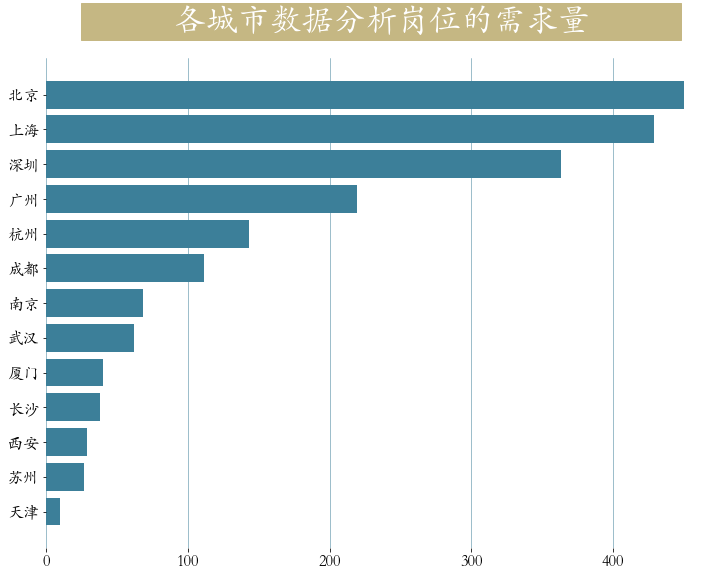

In [23]:
plt.figure(figsize=(12,9))
plt.barh(y = cities.index[::-1],
        width = cities.values[::-1],
        color = '#3c7f99')
plt.box(False) # 不显示边框

plt.title(label='           各城市数据分析岗位的需求量           ', 
          fontsize=32, weight='bold', color='white', 
          backgroundcolor='#c5b783',pad = 30 )

plt.tick_params(labelsize = 16)
plt.grid(axis = 'x',linewidth = 0.5,color = '#3c7f99')

In [24]:
from matplotlib.font_manager import FontManager
fm = FontManager()
[font.name for font in fm.ttflist]

['DejaVu Serif',
 'STIXNonUnicode',
 'cmss10',
 'STIXNonUnicode',
 'STIXSizeFourSym',
 'STIXSizeOneSym',
 'STIXSizeFiveSym',
 'STIXNonUnicode',
 'DejaVu Sans Mono',
 'DejaVu Sans',
 'cmtt10',
 'DejaVu Sans',
 'STIXGeneral',
 'cmr10',
 'STIXSizeOneSym',
 'DejaVu Sans Mono',
 'DejaVu Sans',
 'cmex10',
 'DejaVu Serif',
 'cmsy10',
 'STIXGeneral',
 'DejaVu Sans Mono',
 'STIXSizeTwoSym',
 'DejaVu Sans Display',
 'DejaVu Serif',
 'DejaVu Serif Display',
 'DejaVu Sans Mono',
 'STIXSizeThreeSym',
 'cmb10',
 'STIXGeneral',
 'DejaVu Serif',
 'STIXNonUnicode',
 'STIXSizeTwoSym',
 'STIXSizeFourSym',
 'DejaVu Sans',
 'cmmi10',
 'STIXSizeThreeSym',
 'STIXGeneral',
 'KaiTi',
 'Tw Cen MT Condensed',
 'Kunstler Script',
 'Goudy Old Style',
 'Microsoft JhengHei',
 'Palace Script MT',
 'Californian FB',
 'Bernard MT Condensed',
 'SimSun-ExtB',
 'Segoe UI',
 'Malgun Gothic',
 'Arial Rounded MT Bold',
 'STCaiyun',
 'Lucida Bright',
 'Lucida Sans Typewriter',
 'Segoe Print',
 'Wingdings',
 'Mongolian Baiti',

## <font color='red'>不同领域对数据分析的需求量？（项目实战二招聘数据处理）</font>

In [31]:
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams['font.family'] = 'STKaiti'
job = pd.read_csv('./项目实战二（招聘数据处理）/数据分析岗位.csv')
job["industryField"].value_counts()[:30]

金融             161
移动互联网          141
文娱丨内容          111
电商              92
数据服务            83
移动互联网,电商        76
移动互联网,数据服务      61
移动互联网,金融        58
社交              57
企业服务            53
消费生活            51
移动互联网,教育        50
移动互联网,游戏        47
移动互联网,消费生活      46
游戏              38
电商,移动互联网        37
移动互联网,文娱丨内容     35
移动互联网,社交        35
教育              35
其他              32
汽车丨出行           31
企业服务,数据服务       24
移动互联网,硬件        24
数据服务,移动互联网      23
电商,消费生活         20
硬件              19
移动互联网,企业服务      19
金融,软件开发         18
数据服务,广告营销       17
信息安全,数据服务       16
Name: industryField, dtype: int64

In [32]:
def clean_industry(industry):
    industry = industry.split(",")
    if industry[0]=="移动互联网" and len(industry)>1:
        return industry[1]
    else:
        return industry[0]
    
job["industryField"] = job.industryField.map(clean_industry)
job

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,平均薪资,workYear
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,25k-35k,30.0,5-10年
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,25k-45k,35.0,5-10年
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,3-5年
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,1-3年
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,15k-30k,22.5,3-5年
...,...,...,...,...,...,...,...,...,...,...
1984,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,5k-10k,7.5,3-5年
1985,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,7k-14k,10.5,5-10年
1986,数据中心项目负责人,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,8.0,不限
1987,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-8k,7.0,3-5年


In [34]:
job.industryField.value_counts()[:30]

电商            271
金融            271
数据服务          249
文娱丨内容         149
企业服务          145
移动互联网         141
消费生活          114
社交            103
游戏             96
教育             94
硬件             56
其他             46
医疗丨健康          34
汽车丨出行          33
信息安全           32
广告营销           28
人工智能           23
房产家居           18
软件开发           12
物流丨运输          11
旅游             10
通讯电子            8
工具              8
物联网             5
数据服务、教育         5
电子商务            4
医疗健康            3
电子商务 移动互联网      3
区块链             2
金融 广告营销         2
Name: industryField, dtype: int64

In [35]:
# 获取需求量前10多的领域
industry_index = job["industryField"].value_counts()[:10].index
industry_index

Index(['电商', '金融', '数据服务', '文娱丨内容', '企业服务', '移动互联网', '消费生活', '社交', '游戏', '教育'], dtype='object')

In [38]:
# 数据筛选
industry =job.loc[job["industryField"].isin(industry_index),"industryField"]
industry

0        企业服务
1          金融
2       移动互联网
3       移动互联网
4          电商
        ...  
1984     企业服务
1985     企业服务
1986    文娱丨内容
1987    文娱丨内容
1988    文娱丨内容
Name: industryField, Length: 1633, dtype: object

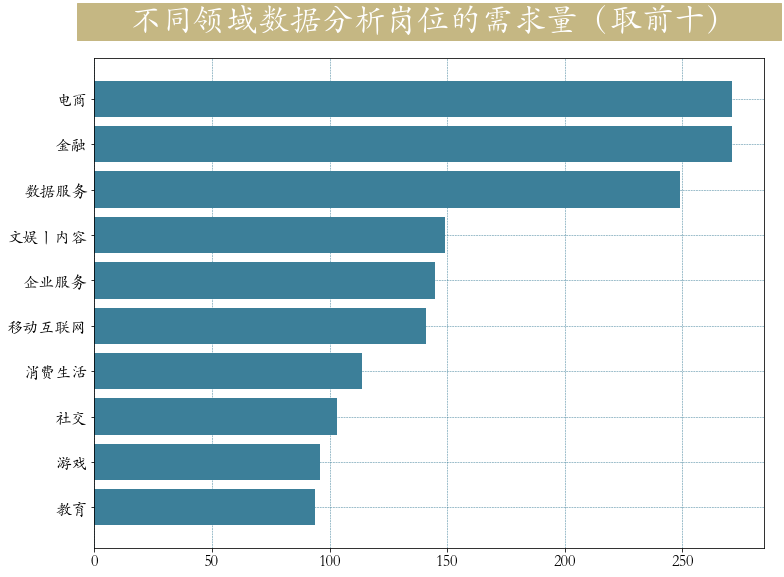

In [37]:
plt.figure(figsize=(12,9))
plt.barh(y = industry_index[::-1],
         width=pd.Series.value_counts(industry.values).values[::-1],
         color = '#3c7f99')
plt.title(label='      不同领域数据分析岗位的需求量（取前十）     ', 
          fontsize=32, weight='bold', color='white', 
          backgroundcolor='#c5b783',ha = 'center',pad = 30)
plt.tick_params(labelsize=16)
plt.grid(lw = 0.5,color = '#3c7f99',ls = '--')

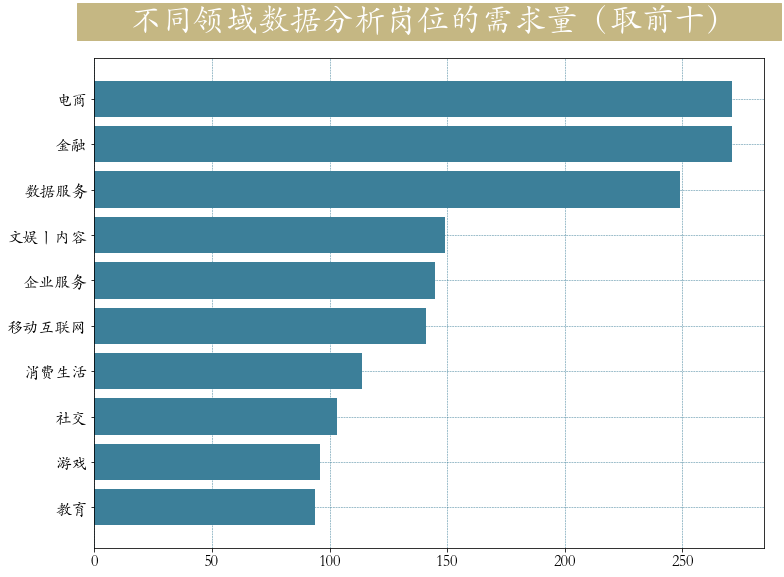

In [41]:
data = job["industryField"].value_counts()[:10]
plt.figure(figsize=(12,9))
plt.barh(y = data.index[::-1],
         width=data.values[::-1],
         color = '#3c7f99')
plt.title(label='      不同领域数据分析岗位的需求量（取前十）     ', 
          fontsize=32, weight='bold', color='white', 
          backgroundcolor='#c5b783',ha = 'center',pad = 30)
plt.tick_params(labelsize=16)
plt.grid(lw = 0.5,color = '#3c7f99',ls = '--')

## <font color='red'>不同城市数据分析薪资情况？（项目实战二招聘数据处理）</font>

In [49]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
job = pd.read_csv('./项目实战二（招聘数据处理）/数据分析岗位.csv')
job

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,平均薪资,workYear
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,25k-35k,30.0,5-10年
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,25k-45k,35.0,5-10年
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,3-5年
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,15k-25k,20.0,1-3年
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,15k-30k,22.5,3-5年
...,...,...,...,...,...,...,...,...,...,...
1984,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,5k-10k,7.5,3-5年
1985,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,7k-14k,10.5,5-10年
1986,数据中心项目负责人,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-10k,8.0,不限
1987,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,6k-8k,7.0,3-5年


In [50]:
city_mean_salary = job.groupby("city")["平均薪资"].mean().sort_values() # 分组聚合运算
city_mean_salary

city
天津     8.450000
西安    11.551724
成都    12.049550
长沙    12.236842
广州    15.246575
武汉    15.903226
苏州    16.148148
南京    16.698529
厦门    18.312500
深圳    20.431129
上海    20.462704
杭州    21.209790
北京    21.432222
Name: 平均薪资, dtype: float64

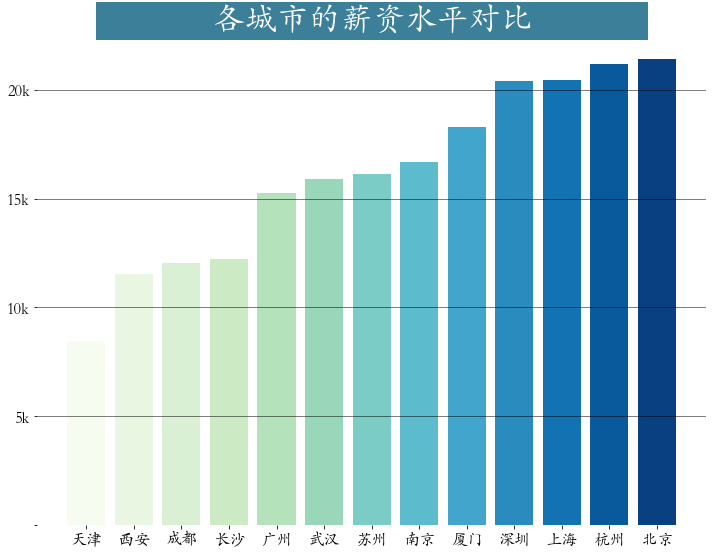

In [53]:
plt.figure(figsize=(12,9))
plt.bar(x = city_salary.index,height = city_salary.values,
       color = plt.cm.GnBu(np.linspace(0,1,len(city_salary))))

plt.title(label='              各城市的薪资水平对比              ', 
         fontsize=32, weight='bold', color='white', backgroundcolor='#3c7f99')
plt.tick_params(labelsize=16)
plt.grid(axis = 'y',linewidth = 0.5,color = 'black')
plt.yticks(ticks = np.arange(0,25,step = 5,),labels = ['','5k','10k','15k','20k'])
plt.box(False) # 去掉边框

## 📄 9-带着问题学pandas.ipynb

## <font color='red'>数据分析师对学历是什么要求？（项目实战二招聘数据处理）</font>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'STKaiti'
job = pd.read_csv('./项目实战二（招聘数据处理）/数据分析岗位.csv')
job

In [ ]:
education = job["education"].value_counts(normalize=True)
education

In [ ]:
plt.figure(figsize=(9,9))

_ = plt.pie(education,# 饼图数据
            labels=education.index, # 标签
            autopct='%0.2f%%',# 自动显示百分比
            wedgeprops=dict(linewidth=10,width = 0.5,edgecolor='green'),
            pctdistance=0.75,
            textprops = dict(fontsize = 20))

_ = plt.title(label='             学历要求            ', 
          fontsize=32, weight='bold', 
          color='white', backgroundcolor='#c5b783',pad = 10)

## <font color='red'>工作经验与薪资是什么关系？（项目实战二招聘数据处理）</font>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
job = pd.read_csv('./项目实战二（招聘数据处理）/数据分析岗位.csv')
job

In [ ]:
work_salary = job.pivot_table(index="city",columns="workYear",values="平均薪资") # 透视表
work_salary
work_salary = work_salary[["应届毕业生","1-3年","3-5年","5-10年"]]\
              .sort_values(by = '5-10年',ascending = False) # 筛选一部分工作经验
work_salary

In [ ]:
data = work_salary.values
display(data.round(2))
data = np.repeat(data,4,axis = 1).round(2) # 重复4次，目的画图，美观，图片宽度拉大
display(data)

In [ ]:
'''supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 
'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Greens',
'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired',
'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r',
'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r', 'cool', 'cool_r', 'coolwarm', 'coolwarm_r', 'copper', 'copper_r', 'cubehelix', 'cubehelix_r', 'flag', 'flag_r', 'gist_earth', 'gist_earth_r', 'gist_gray', 'gist_gray_r', 'gist_heat', 'gist_heat_r', 'gist_ncar', 'gist_ncar_r', 'gist_rainbow', 'gist_rainbow_r', 'gist_stern', 'gist_stern_r', 'gist_yarg', 'gist_yarg_r', 'gnuplot', 'gnuplot2', 'gnuplot2_r', 'gnuplot_r', 'gray', 'gray_r', 'hot', 'hot_r', 'hsv', 'hsv_r', 'inferno', 'inferno_r', 'jet', 'jet_r', 'magma', 'magma_r', 'nipy_spectral', 'nipy_spectral_r', 'ocean', 'ocean_r', 'pink', 'pink_r', 'plasma', 'plasma_r', 'prism', 'prism_r', 'rainbow', 'rainbow_r', 'seismic', 'seismic_r', 'spring', 'spring_r', 'summer', 'summer_r', 'tab10', 'tab10_r', 'tab20', 'tab20_r', 'tab20b', 'tab20b_r', 'tab20c', 'tab20c_r', 'terrain', 'terrain_r', 'turbo', 'turbo_r', 'twilight', 'twilight_r', 'twilight_shifted', 
'twilight_shifted_r', 'viridis', 'viridis_r', 'winter', 'winter_r' '''
plt.figure(figsize=(12,9))
plt.imshow(data,cmap='Purples')
plt.yticks(np.arange(13),work_salary.index)
plt.xticks(np.array([1.5,5.5,9.5,13.5]),work_salary.columns)
_ = plt.tick_params(labelsize = 16)
# 绘制文本
h,w = data.shape
for x in range(w):
    for y in range(h):
        if (x % 4 == 0) and (~np.isnan(data[y,x])):
            text = plt.text(x + 1.5, y, 
                            round(data[y,x],1),
                            ha="center", 
                            va="center", 
                            color='r',
                            fontsize = 16)
            
plt.colorbar(shrink = 0.85)
_ = plt.title(label='              工作经验与薪资关系              ', 
         fontsize=32, weight='bold', color='white', 
          backgroundcolor='#3c7f99',pad = 30)

## <font color='red'>技能与薪资是什么关系？（项目实战二招聘数据处理）</font>

In [ ]:
import pandas as pd
job = pd.read_csv('./项目实战二（招聘数据处理）/job.csv',encoding='gbk')
job.head(10)

In [ ]:
job['job_detail'][100]

In [ ]:
# 数据分析岗位筛选
cond = job["positionName"].str.contains("数据|分析|BI|bi")
job = job[cond].copy()
# 薪资转换，区间转平均薪资
job['salary'] = job["salary"].str.lower().str.extract(r'(\d+)k-(\d+)k').applymap(lambda x : int(x)).mean(axis = 1)
job

In [ ]:
job["job_detail"] = job["job_detail"].str.lower()  #将字符串小写化，并将缺失值赋值为空字符串
job["Python"] = job["job_detail"].map(lambda x:1 if ('python' in x) else 0)
job["SQL"] = job["job_detail"].map(lambda x:1 if ('sql' in x) or ('hive' in x)  else 0)
job["Tableau"] = job["job_detail"].map(lambda x:1 if 'tableau' in x  else 0)
job["Excel"] = job["job_detail"].map(lambda x:1 if 'excel' in x  else 0)
job['SPSS/SAS'] = job['job_detail'].map(lambda x:1 if ('spss' in x) or ('sas' in x) else 0)
job

In [ ]:
plt.figure(figsize=(12,8))
_ = plt.boxplot([job.loc[job['Python'].astype('bool'),'salary'],
                 job.loc[job['Excel'].astype('bool'),'salary']],
                vert=False,
                labels=['Python','Excel'])
plt.tick_params(axis="both",labelsize=20)

In [ ]:
plt.figure(figsize=(12,8))
plt.boxplot([job.loc[job['Python'].astype('bool'),'salary'],
             job.loc[job['SQL'].astype('bool'),'salary'],
             job.loc[job['Excel'].astype('bool'),'salary'],
             job.loc[job['Tableau'].astype('bool'),'salary'],
             job.loc[job['SPSS/SAS'].astype('bool'),'salary'],],
            vert = False,labels=['Python','SQL','Excel','Tableau','SPSS/SAS'])

plt.title(label='             不同技能的薪资水平对比            ', 
          fontsize=32, weight='bold', color='white', 
          backgroundcolor='#c5b783',pad = 30)
plt.tick_params(axis="both",labelsize=20)
plt.grid(axis = 'x',linewidth = 0.75)
plt.xticks(np.arange(0,161,20), [str(i)+"k" for i in range(0,161,20)])
plt.box(False)
plt.xlabel('工资', fontsize=18)
_ = plt.ylabel('技能', fontsize=18)

In [ ]:
cond = job['salary'] == 160
job[cond]

## <font color='red'>大公司侧重什么技能？（项目实战二招聘数据处理）</font>

In [ ]:
import pandas as pd
job = pd.read_csv('./项目实战二（招聘数据处理）/job.csv',encoding='gbk')
# 数据分析岗位筛选
cond = job["positionName"].str.contains("数据|分析|BI|bi")
job = job[cond].copy()
# 薪资转换，区间转平均薪资
job['salary'] = job["salary"].str.lower().str.extract(r'(\d+)k-(\d+)k').applymap(lambda x : int(x)).mean(axis = 1)

job["job_detail"] = job["job_detail"].str.lower()  #将字符串小写化，并将缺失值赋值为空字符串
job["Python"] = job["job_detail"].map(lambda x:1 if ('python' in x) else 0)
job["SQL"] = job["job_detail"].map(lambda x:1 if ('sql' in x) or ('hive' in x)  else 0)
job["Tableau"] = job["job_detail"].map(lambda x:1 if 'tableau' in x  else 0)
job["Excel"] = job["job_detail"].map(lambda x:1 if 'excel' in x  else 0)
job['SPSS/SAS'] = job['job_detail'].map(lambda x:1 if ('spss' in x) or ('sas' in x) else 0)
job

In [ ]:
skill_count = job[job['companySize'] == '2000人以上'][['Python','SQL','Tableau','Excel','SPSS/SAS']].sum()
skill_count

In [ ]:
skill_count/skill_count.max()

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,9))
plt.bar(np.arange(5),skill_count,
        tick_label = ['Python','SQL','Tableau','Excel','SPSS/SAS'],
        width = 0.5,
        color = plt.cm.BuPu(skill_count/skill_count.max()))

_ = plt.title(label='             大公司对技能的要求         ', 
          fontsize=32, weight='bold', color='white', 
          backgroundcolor='#c5b783',pad = 30)
plt.tick_params(labelsize=16,)
plt.grid(axis = 'y')
plt.box(False)

## <font color='red'>大中小公司招聘差异？（项目实战二招聘数据处理）</font>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
job = pd.read_csv('./项目实战二（招聘数据处理）/job.csv',encoding='gbk')
# 数据分析岗位筛选
cond = job["positionName"].str.contains("数据|分析|BI|bi")
job = job[cond].copy()
# 薪资转换，区间转平均薪资
job['salary'] = job["salary"].str.lower().str.extract(r'(\d+)k-(\d+)k').applymap(lambda x : int(x)).mean(axis = 1)
job

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear,job_detail
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,30.0,5-10年,\n1.搭建数据指标框架，完整并准确反映业务趋势和变化，及时发现和定位问题\n2.独立完成数...
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,35.0,5-10年,\n工作职责：\n1. 负责建立交易平台日常分析体系，包括核心指标体系、报表体系，专题活动分...
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,20.0,3-5年,\n职位描述：1.对亿计的办公用户数据进行深度挖掘，引导产品、运营，并能实际应用到业务中带来...
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,20.0,1-3年,\n工作职责：-负责日常运营、业务数据等分析-针对产品需求做深入的数据分析报告，分析用户行为...
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,22.5,3-5年,\n【数据分析师岗】\n岗位要求：\n1、构建及维护客户体验相关数据报表平台；\n2、与大数...
...,...,...,...,...,...,...,...,...,...,...
3601,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,7.5,3-5年,\n工作职责：\n1、数据需求分析、资源规划、采集清洗、挖掘分析与算法设计；数据资源建设与管...
3629,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,10.5,5-10年,\n1.?根据公司发展战略方向，收集行业应用相关信息，为新产品规划、设计提供决策支持和依据；...
3674,数据中心项目负责人,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,8.0,不限,\n 职位职责：\n1. 业务专家团队日常人员管理、例会文件准备、绩效核算等基...
3681,数据运营分析专员,字节跳动,天津,2000人以上,本科,C轮,文娱丨内容,7.0,3-5年,\n 职位职责：\n1、协助数据分析团队项目的测试及开展，了解公司各部门的组织...


In [8]:
# 160K薪资太高，过滤
cond = job['salary'] != 160
job = job[cond]

In [9]:
job.workYear.value_counts()

3-5年     769
1-3年     513
5-10年    281
不限       211
应届毕业生    174
1年以下      33
10年以上      7
Name: workYear, dtype: int64

In [12]:
from matplotlib import gridspec # 画图时候，可以拆分区域，不同区域绘制不同内容
plt.rcParams['font.family'] = 'STKaiti'

workYear_map = {
    "5-10年": 5,
    "3-5年": 4,
    "1-3年": 3,
    "1年以下": 2,
    "应届毕业生": 1}

color_map = {
    5:"#ff0000",
    4:"#ffa500",
    3:"#c5b783",
    2:"#3c7f99",
    1:"#0000cd"}
cond = job.workYear.isin(workYear_map)
result = job[cond].copy()
result

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear,job_detail
0,高级数据分析师,拉勾网,北京,500-2000人,本科,D轮及以上,企业服务,30.0,5-10年,\n1.搭建数据指标框架，完整并准确反映业务趋势和变化，及时发现和定位问题\n2.独立完成数...
1,数据分析师,OK Group,北京,500-2000人,大专,B轮,金融,35.0,5-10年,\n工作职责：\n1. 负责建立交易平台日常分析体系，包括核心指标体系、报表体系，专题活动分...
2,高级数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,20.0,3-5年,\n职位描述：1.对亿计的办公用户数据进行深度挖掘，引导产品、运营，并能实际应用到业务中带来...
3,数据分析师,金山办公软件,北京,2000人以上,本科,上市公司,移动互联网,20.0,1-3年,\n工作职责：-负责日常运营、业务数据等分析-针对产品需求做深入的数据分析报告，分析用户行为...
4,数据分析师,京东集团,北京,2000人以上,本科,上市公司,电商,22.5,3-5年,\n【数据分析师岗】\n岗位要求：\n1、构建及维护客户体验相关数据报表平台；\n2、与大数...
...,...,...,...,...,...,...,...,...,...,...
3588,产品经理数据方向,神州商龙,天津,500-2000人,大专,上市公司,"移动互联网,消费生活",12.0,3-5年,\n岗位职责：\n1.负责数据产品的需求分析、原型设计、产品文档撰写及协调研发、测试完成产品...
3594,数据运营经理,安居客,天津,2000人以上,本科,不需要融资,"移动互联网,企业服务",12.5,5-10年,"\n 岗位职责：\n1. 针对业务目标,依托大数据平台,制定产品整体的数据化运..."
3601,数据产品经理,北京天宇,天津,500-2000人,本科,未融资,企业服务,7.5,3-5年,\n工作职责：\n1、数据需求分析、资源规划、采集清洗、挖掘分析与算法设计；数据资源建设与管...
3629,需求分析工程师,易景环境,天津,500-2000人,大专,上市公司,企业服务,10.5,5-10年,\n1.?根据公司发展战略方向，收集行业应用相关信息，为新产品规划、设计提供决策支持和依据；...


In [17]:
result.loc[:,'workYear'] = job['workYear'].map(workYear_map)
# 根据companySize进行排序，人数从多到少
result['companySize'] = result['companySize'].astype('category')
list_custom = ['2000人以上', '500-2000人','150-500人','50-150人','15-50人','少于15人']
result['companySize'] = result['companySize'].cat.reorder_categories(list_custom)
result.sort_values(by = 'companySize',inplace = True,ascending = False)
result

,positionName,companyShortName,city,companySize,education,financeStage,industryField,salary,workYear,job_detail
1603,数据建模工程师,创客矩阵咨询,杭州,少于15人,不限,未融资,数据服务、教育,22.5,1.0,\n1.远程工作2.项目经验多者优先3.科研竞赛成果多者优先4.接受全职投递5.具体可以详细...
700,数据分析师,拓端数据,上海,少于15人,本科,未融资,"数据服务,电商",21.5,3.0,\n 1、了解移动行业基础知识，熟练使用一种数据统计分析工具，能快速有效的给出...
403,数据分析师,脱水,北京,少于15人,本科,天使轮,"移动互联网,教育",18.0,3.0,\n 职位描述\n1、对社交业务、产品、策略效果、人群等进行深入分析，为产品提...
394,数据分析实习生,万山数据,北京,少于15人,本科,未融资,数据服务、企业服务,4.0,1.0,\n工作内容:数据梳理数据处理规则编写基础统计基本要求:对数据敏感了解SQL优先会Excel...
1539,数据分析师,汇数智通,杭州,少于15人,本科,A轮,移动互联网,4.5,1.0,\n 不能实习半年以上，勿扰！！！\n\n职位描述\n\n 1、 学习并掌握运...
...,...,...,...,...,...,...,...,...,...,...
703,高级数据分析师,SAS,上海,2000人以上,硕士,不需要融资,人工智能,40.0,5.0,\n职责：\n1、 作为数据分析带头人，带领数据科学团队进行大数据挖掘与建模项目研发；\n2...
1375,大数据分析师（会员画像）,钱大妈,广州,2000人以上,本科,D轮及以上,消费生活,23.0,5.0,\n岗位职责:\n1、负责会员标签体系搭建及研发，同时负责消费者画像分析；\n2、负责调研业...
699,数据分析师,掌门1对1在线教育,上海,2000人以上,本科,D轮及以上,"移动互联网,教育",16.5,4.0,\n岗位职责：\n1. 对新媒体推广业务数据进行处理和分析，以目标为导向，主动从业务角度出发...
695,数据分析师（会员营销方向）,永辉云创科技有限公司,上海,2000人以上,本科,D轮及以上,"电商,消费生活",30.0,4.0,\n 岗位职责：\n\n\n 构建会员与营销业务数据分析体系，搭建数据指标体系...


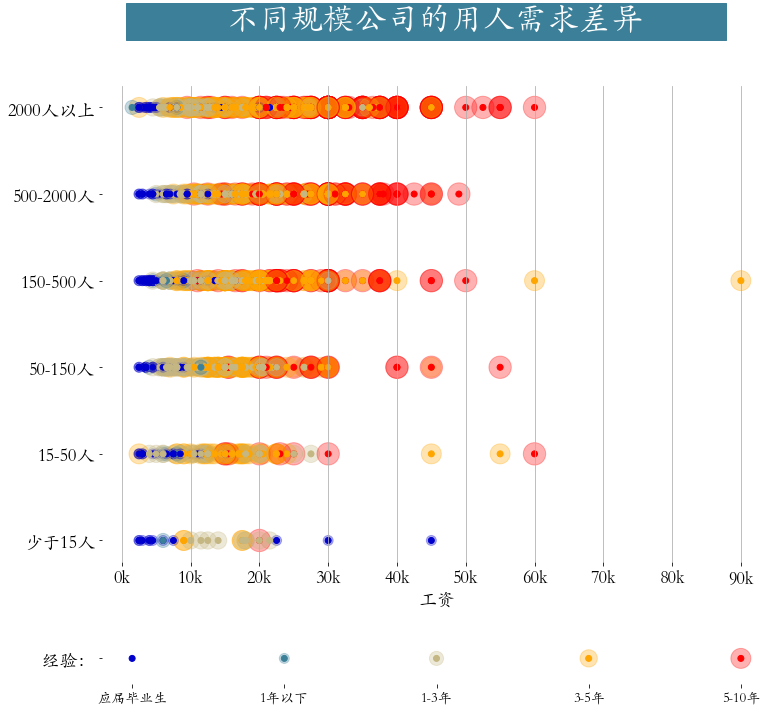

In [25]:
plt.figure(figsize=(12,11))
gs = gridspec.GridSpec(10,1)
plt.subplot(gs[:8])
plt.suptitle(t='            不同规模公司的用人需求差异          ', 
         fontsize=32, 
         weight='bold', color='white', backgroundcolor='#3c7f99')
plt.scatter(result.salary,result.companySize,
            c = result.workYear.map(color_map),
            s = (result.workYear*100),alpha = 0.3)
plt.scatter(result.salary,result.companySize,
            c = result.workYear.map(color_map))
plt.grid(axis = 'x')
plt.xticks(np.arange(0,100,10), [str(i)+"k" for i in range(0,100,10)])
plt.xlabel('工资', fontsize=18)
plt.box(False)
plt.tick_params(labelsize = 18)


# 绘制底部标记
plt.subplot(gs[9:])
x = np.arange(5)[::-1]
y = np.zeros(len(x))
s = x*100
plt.scatter(x,y,s=s,c=color_map.values(),alpha=0.3)
plt.scatter(x,y,c=color_map.values())
plt.box(False)
plt.xticks(ticks=x,labels=list(workYear_map.keys()),fontsize=14)
plt.yticks(np.arange(1),labels=['  经验：'],fontsize=18)
plt.savefig('./85-大中小公司招聘差异？.png',bbox_inches = 'tight',dpi =200)

In [21]:
list(workYear_map.keys())

['5-10年', '3-5年', '1-3年', '1年以下', '应届毕业生']

In [22]:
x

array([4, 3, 2, 1, 0])

In [27]:
result.workYear * 100

1603    100.0
700     300.0
403     300.0
394     100.0
1539    100.0
        ...  
703     500.0
1375    500.0
699     400.0
695     400.0
3681    400.0
Name: workYear, Length: 1770, dtype: float64

## <font color='red'>低压停电事件统计计数？（项目实战）</font>

统计所有疑似<font color = 'red'>低压停电</font>导致的停上电事件，该类事件满足如下条件:   

----

在同变压器下，存在至少 3 个不同用户，且它们<font color='red'>两两之间</font>的停电时间相近 (小于等于60 秒)。

----
这类停电事件称为低压停电导致的停上电事件，筛选出所有该类事件输出为 incident.csv

In [61]:
import pandas as pd
data = pd.read_csv('./美电网数据/use1.csv')
display(data.head(10),data.shape)

,byq_id,user_id,start,end
0,usa310,51612343,2020-07-21 10:11:07,2020-07-21 20:03:39
1,usa310,47568864,2020-07-22 21:48:22,2020-07-23 04:33:42
2,usa310,88757790,2020-08-06 00:04:32,2020-08-06 07:41:38
3,usa310,47790724,2020-08-11 00:11:02,2020-08-11 07:29:12
4,usa310,77769003,2020-08-13 06:33:21,2020-08-13 15:11:54
5,usa310,88757790,2020-08-16 01:37:39,2020-08-16 06:45:39
6,usa310,51612343,2020-08-17 08:45:04,2020-08-17 20:08:06
7,usa310,94859164,2020-08-19 06:47:33,2020-08-19 14:24:40
8,usa310,51612343,2020-08-19 12:35:21,2020-08-19 16:04:07
9,usa310,84680995,2020-09-11 05:58:00,2020-09-11 08:38:17


(100013, 4)

In [62]:
print(data.duplicated().sum()) # 查看是否有重复数据

0


In [63]:
# 时间类型转换，便于计算
display(data.dtypes)
data['start'] = pd.to_datetime(data['start'])
data['end'] = pd.to_datetime(data['end'])
display(data.dtypes)
data.head(10)

byq_id     object
user_id     int64
start      object
end        object
dtype: object

byq_id             object
user_id             int64
start      datetime64[ns]
end        datetime64[ns]
dtype: object

,byq_id,user_id,start,end
0,usa310,51612343,2020-07-21 10:11:07,2020-07-21 20:03:39
1,usa310,47568864,2020-07-22 21:48:22,2020-07-23 04:33:42
2,usa310,88757790,2020-08-06 00:04:32,2020-08-06 07:41:38
3,usa310,47790724,2020-08-11 00:11:02,2020-08-11 07:29:12
4,usa310,77769003,2020-08-13 06:33:21,2020-08-13 15:11:54
5,usa310,88757790,2020-08-16 01:37:39,2020-08-16 06:45:39
6,usa310,51612343,2020-08-17 08:45:04,2020-08-17 20:08:06
7,usa310,94859164,2020-08-19 06:47:33,2020-08-19 14:24:40
8,usa310,51612343,2020-08-19 12:35:21,2020-08-19 16:04:07
9,usa310,84680995,2020-09-11 05:58:00,2020-09-11 08:38:17


In [64]:
def convert(x):
    x.sort_values(by = 'start').reset_index(drop = True,inplace = True)# 新的DataFrame
    r1 = x['start'].diff(1).dt.total_seconds().fillna(method = 'bfill') <= 60
    r2 = x['start'].diff(-1).dt.total_seconds().fillna(method = 'bfill') >= -60
    return pd.DataFrame({'byq_id':x['byq_id'],
                         'user_id':x['user_id'],
                         'start':x['start'],
                         'end':x['end'],
                         '低压停电':r1|r2})
result = data.groupby(by = 'byq_id').apply(convert)
result

,byq_id,user_id,start,end,低压停电
0,usa310,51612343,2020-07-21 10:11:07,2020-07-21 20:03:39,False
1,usa310,47568864,2020-07-22 21:48:22,2020-07-23 04:33:42,False
2,usa310,88757790,2020-08-06 00:04:32,2020-08-06 07:41:38,False
3,usa310,47790724,2020-08-11 00:11:02,2020-08-11 07:29:12,False
4,usa310,77769003,2020-08-13 06:33:21,2020-08-13 15:11:54,False
...,...,...,...,...,...
100008,usa2299,91443159,2022-02-15 05:19:20,2022-02-15 05:38:15,False
100009,usa2299,31183863,2022-02-25 04:36:01,2022-02-25 06:17:12,False
100010,usa2299,33343001,2022-03-19 16:19:50,2022-03-20 00:41:38,False
100011,usa2299,43598082,2022-03-29 18:56:19,2022-03-30 05:49:01,False


In [65]:
cond = result['低压停电']
res1 = result[cond]
res1

,byq_id,user_id,start,end,低压停电
173,usa313,85477746,2021-04-14 03:06:25,2021-04-14 09:45:01,True
174,usa313,64874783,2021-04-14 03:06:49,2021-04-14 06:32:40,True
3229,usa366,88569121,2020-10-12 13:46:57,2020-10-12 16:12:07,True
3230,usa366,42500277,2020-10-12 13:47:36,2020-10-12 17:29:02,True
4812,usa401,46150911,2021-12-14 03:42:52,2021-12-14 12:52:09,True
...,...,...,...,...,...
92079,usa2140,80986485,2022-01-06 09:18:35,2022-01-06 20:39:07,True
96312,usa2237,58340514,2021-04-10 02:21:40,2021-04-10 06:55:28,True
96313,usa2237,32474070,2021-04-10 02:21:51,2021-04-10 02:40:59,True
98529,usa2272,70506347,2021-01-02 16:03:42,2021-01-02 17:23:26,True


In [66]:
cond2 = res1.groupby(by = 'byq_id').size() >= 3
display(cond2)
byq_ids = cond2[cond2].index
display(byq_ids)
cond = res1['byq_id'].isin(byq_ids)
res2 = res1[cond]
display(res2)
res2.to_csv('./美电网数据/accident.csv',index=False)

byq_id
usa1048    False
usa1156     True
usa1352    False
usa1386    False
usa1471     True
usa1488     True
usa1682    False
usa1718    False
usa1745    False
usa1957    False
usa1992    False
usa2010     True
usa2140     True
usa2237    False
usa2272    False
usa313     False
usa366     False
usa401     False
usa479     False
usa602      True
usa786     False
usa798     False
usa814     False
usa833      True
usa855     False
usa960      True
usa988     False
dtype: bool

Index(['usa1156', 'usa1471', 'usa1488', 'usa2010', 'usa2140', 'usa602',
       'usa833', 'usa960'],
      dtype='object', name='byq_id')

,byq_id,user_id,start,end,低压停电
14932,usa602,91813207,2021-11-14 08:57:02,2021-11-14 15:01:44,True
14933,usa602,47408698,2021-11-14 08:57:22,2021-11-14 15:01:44,True
14934,usa602,71795040,2021-11-14 08:57:54,2021-11-14 15:01:46,True
25611,usa833,54904160,2021-05-23 04:26:13,2021-05-23 07:21:21,True
25612,usa833,88079207,2021-05-23 04:26:18,2021-05-23 07:21:23,True
25613,usa833,39364978,2021-05-23 04:26:55,2021-05-23 07:21:51,True
25614,usa833,88079207,2021-05-23 04:27:09,2021-05-23 07:21:57,True
25615,usa833,85915732,2021-05-23 04:27:17,2021-05-23 07:22:06,True
32368,usa960,58430119,2021-08-08 00:26:00,2021-08-08 08:10:01,True
32369,usa960,58430119,2021-08-08 00:26:01,2021-08-08 08:10:02,True


In [67]:
res2.shape

(33, 5)

## <font color='red'>用户投诉预警分析？（项目实战）</font>

为进行用户投诉预警分析，请统计所有用户<font color='red' size = 5>任意 60 天内</font>的最大停电次数,  

将<font color='green' size=5>最大停电次数超过3(含3 次)</font>的用户编号和最大停电次数保存为 alert.csv  

输出表结构：

| 用户编号 | 最大停电次数 |
| ------- | ------- |
| 26572846| 3| 
| 26581523 | 3 | 
| …… | …… | 

In [254]:
import pandas as pd
data = pd.read_csv('./美电网数据/use1.csv')
data['start'] = pd.to_datetime(data['start']).dt.date
data['start'] = pd.to_datetime(data['start'])
data.set_index('start',inplace=True)
display(data.head(10),data.dtypes)

,byq_id,user_id,end
start,,,
2020-07-21,usa310,51612343,2020-07-21 20:03:39
2020-07-22,usa310,47568864,2020-07-23 04:33:42
2020-08-06,usa310,88757790,2020-08-06 07:41:38
2020-08-11,usa310,47790724,2020-08-11 07:29:12
2020-08-13,usa310,77769003,2020-08-13 15:11:54
2020-08-16,usa310,88757790,2020-08-16 06:45:39
2020-08-17,usa310,51612343,2020-08-17 20:08:06
2020-08-19,usa310,94859164,2020-08-19 14:24:40
2020-08-19,usa310,51612343,2020-08-19 16:04:07


byq_id     object
user_id     int64
end        object
dtype: object

In [255]:
data.index

DatetimeIndex(['2020-07-21', '2020-07-22', '2020-08-06', '2020-08-11',
               '2020-08-13', '2020-08-16', '2020-08-17', '2020-08-19',
               '2020-08-19', '2020-09-11',
               ...
               '2021-12-21', '2022-01-20', '2022-02-04', '2022-02-09',
               '2022-02-10', '2022-02-15', '2022-02-25', '2022-03-19',
               '2022-03-29', '2022-03-30'],
              dtype='datetime64[ns]', name='start', length=100013, freq=None)

In [256]:
%%time
def convert(df):
    df.sort_index(inplace = True) # 按照时间排序，从小到大
    m = 0
    for i in range(len(df)):
        res = df.iloc[i:].resample('60D').size()
        if m < res.max():
            m = res.max()
    return m
result = data.groupby(by = 'user_id').apply(convert).to_frame('任意60天内最大停电次数')
result

CPU times: total: 1min 18s
Wall time: 1min 18s


,任意60天内最大停电次数
user_id,
26546693,1
26546946,2
26549851,2
26551970,1
26553565,2
...,...
99984220,2
99990076,2
99992153,2


In [261]:
cond = result['任意60天内最大停电次数'] >= 3
res = result[cond].reset_index()
res.columns = ['用户编号','最大停电次数']
display(res)
res.to_csv('./美电网数据/alert.csv',index=False)

,用户编号,最大停电次数
0,26572846,3
1,26581523,3
2,26588169,3
3,26612555,3
4,26643756,3
...,...,...
3328,99835314,3
3329,99845560,3
3330,99897269,3
3331,99912491,3


In [257]:
result.max()

任意60天内最大停电次数    6
dtype: int64

In [258]:
result.idxmax()

任意60天内最大停电次数    38474295
dtype: int64

In [259]:
cond = data['user_id'] == 38474295
df = data[cond]
df

,byq_id,user_id,end
start,,,
2021-03-14,usa1738,38474295,2021-03-14 14:56:22
2021-06-11,usa1738,38474295,2021-06-11 22:05:40
2021-06-20,usa1738,38474295,2021-06-20 15:54:04
2021-09-17,usa1738,38474295,2021-09-17 07:21:43
2021-10-15,usa1738,38474295,2021-10-15 14:31:45
2021-12-18,usa1738,38474295,2021-12-18 15:32:42
2021-12-31,usa1738,38474295,2022-01-01 02:26:52
2022-01-23,usa1738,38474295,2022-01-23 03:33:23
2022-01-25,usa1738,38474295,2022-01-25 16:25:57


In [260]:
df.resample('60D').size()

start
2021-03-14    1
2021-05-13    2
2021-07-12    0
2021-09-10    2
2021-11-09    2
2022-01-08    4
Freq: 60D, dtype: int64

In [263]:
cond = data['user_id'] == 38474295    
df1 = data[cond].copy()
display(df1)
def convert(item):
#     print('+++++++++++++++++++++++',item.size)
#     display(item)
    return item.size 
m = 0
for i in range(len(df1)):
    res = df1.iloc[i:].resample('60D')['user_id'].apply(convert)
    print('--------------------------')
    if m < res.max():
        m = res.max()
    display(res)
print('*'*30,m,'*'*30)

,byq_id,user_id,end
start,,,
2021-03-14,usa1738,38474295,2021-03-14 14:56:22
2021-06-11,usa1738,38474295,2021-06-11 22:05:40
2021-06-20,usa1738,38474295,2021-06-20 15:54:04
2021-09-17,usa1738,38474295,2021-09-17 07:21:43
2021-10-15,usa1738,38474295,2021-10-15 14:31:45
2021-12-18,usa1738,38474295,2021-12-18 15:32:42
2021-12-31,usa1738,38474295,2022-01-01 02:26:52
2022-01-23,usa1738,38474295,2022-01-23 03:33:23
2022-01-25,usa1738,38474295,2022-01-25 16:25:57


--------------------------


start
2021-03-14    1
2021-05-13    2
2021-07-12    0
2021-09-10    2
2021-11-09    2
2022-01-08    4
Freq: 60D, Name: user_id, dtype: int64

--------------------------


start
2021-06-11    2
2021-08-10    1
2021-10-09    1
2021-12-08    5
2022-02-06    1
Freq: 60D, Name: user_id, dtype: int64

...

--------------------------


start
2022-01-27    2
Freq: 60D, Name: user_id, dtype: int64

--------------------------


start
2022-02-08    1
Freq: 60D, Name: user_id, dtype: int64

****************************** 6 ******************************


## <font color='red'>企业日用电量环比同比计算？（项目实战）</font>

  计算每个企业日用电量22年环比增幅百分比，公式：  
  
<font size = 5 color='red'>（当日-前1日）/ 前1日 x 100</font>  

计算每个企业22年相比21年日电量（用月电量除以当月天数）同比增幅百分比，公式：  

<font size = 5 color='red'>(当日-去年同日) / 去年同日 x 100</font>

### 数据加载

In [147]:
import numpy as np
import pandas as pd
df2021 = pd.read_csv('./企业用电运营分析/2021企业月用电量.csv')
df2022 = pd.read_csv('./企业用电运营分析/2022企业日用电量.csv')
display(df2021,df2022)

,企业,日期,2021月用电量
0,4d7d7e65d38c405d1d8a,202103,21429.333230
1,ac757c17538580912f10,202103,95181.387260
2,ac757c17538580912f10,202104,85638.881330
3,ac757c17538580912f10,202105,73368.127900
4,ac757c17538580912f10,202106,111745.218500
...,...,...,...
4378,a5da992069416f468639,202104,4219.088000
4379,a5da992069416f468639,202105,4105.876774
4380,a5da992069416f468639,202106,4886.844000
4381,a5da992069416f468639,202107,4736.982903


,企业,日期,2022日用电量
0,03113b33e2390de0dab3,2022-03-01,452.5368
1,03113b33e2390de0dab3,2022-03-02,487.1256
2,03113b33e2390de0dab3,2022-03-03,512.1064
3,03113b33e2390de0dab3,2022-03-04,479.4392
4,03113b33e2390de0dab3,2022-03-05,185.4344
...,...,...,...
113683,fb17dcdbff03dc69180e,2022-07-31,708.1096
113684,fb17dcdbff03dc69180e,2022-08-01,956.9568
113685,fb17dcdbff03dc69180e,2022-08-02,1034.7816
113686,fb17dcdbff03dc69180e,2022-08-03,912.7600


### 月份处理

In [148]:
df2022['日期'] = pd.to_datetime(df2022['日期'])
df2022['月'] = df2022['日期'].dt.month
df2021['日期'] = pd.to_datetime([m + '01' for m in df2021['日期'].astype('str')])
df2021['月'] = df2021['日期'].dt.month
display(df2021,df2022)

,企业,日期,2021月用电量,月
0,4d7d7e65d38c405d1d8a,2021-03-01,21429.333230,3
1,ac757c17538580912f10,2021-03-01,95181.387260,3
2,ac757c17538580912f10,2021-04-01,85638.881330,4
3,ac757c17538580912f10,2021-05-01,73368.127900,5
4,ac757c17538580912f10,2021-06-01,111745.218500,6
...,...,...,...,...
4378,a5da992069416f468639,2021-04-01,4219.088000,4
4379,a5da992069416f468639,2021-05-01,4105.876774,5
4380,a5da992069416f468639,2021-06-01,4886.844000,6
4381,a5da992069416f468639,2021-07-01,4736.982903,7


,企业,日期,2022日用电量,月
0,03113b33e2390de0dab3,2022-03-01,452.5368,3
1,03113b33e2390de0dab3,2022-03-02,487.1256,3
2,03113b33e2390de0dab3,2022-03-03,512.1064,3
3,03113b33e2390de0dab3,2022-03-04,479.4392,3
4,03113b33e2390de0dab3,2022-03-05,185.4344,3
...,...,...,...,...
113683,fb17dcdbff03dc69180e,2022-07-31,708.1096,7
113684,fb17dcdbff03dc69180e,2022-08-01,956.9568,8
113685,fb17dcdbff03dc69180e,2022-08-02,1034.7816,8
113686,fb17dcdbff03dc69180e,2022-08-03,912.7600,8


### 计算企业2021年日用电量

In [149]:
%%time
def func(gp):
    name = gp['企业'].iloc[0]
    month = gp['日期'].dt.month.iloc[0]
    days = gp['日期'].dt.days_in_month.iloc[0]
    cond = (df2021['企业'] == name) & (df2021['月'] == month)
    gp['2021日用电量'] = (df2021.loc[cond,'2021月用电量']/days).iloc[0].round(4)
    return gp
result = df2022.groupby(by = ['企业','月']).apply(func)
result

CPU times: total: 6.31 s
Wall time: 6.35 s


,企业,日期,2022日用电量,月,2021日用电量
0,03113b33e2390de0dab3,2022-03-01,452.5368,3,42.4776
1,03113b33e2390de0dab3,2022-03-02,487.1256,3,42.4776
2,03113b33e2390de0dab3,2022-03-03,512.1064,3,42.4776
3,03113b33e2390de0dab3,2022-03-04,479.4392,3,42.4776
4,03113b33e2390de0dab3,2022-03-05,185.4344,3,42.4776
...,...,...,...,...,...
113683,fb17dcdbff03dc69180e,2022-07-31,708.1096,7,153.6457
113684,fb17dcdbff03dc69180e,2022-08-01,956.9568,8,121.3824
113685,fb17dcdbff03dc69180e,2022-08-02,1034.7816,8,121.3824
113686,fb17dcdbff03dc69180e,2022-08-03,912.7600,8,121.3824


### 环比计算

In [150]:
result['环比'] = ((result['2022日用电量'] - result['2022日用电量'].shift(1)) 
                /result['2022日用电量'].shift(1) * 100).round(4)
result

,企业,日期,2022日用电量,月,2021日用电量,环比
0,03113b33e2390de0dab3,2022-03-01,452.5368,3,42.4776,NaN
1,03113b33e2390de0dab3,2022-03-02,487.1256,3,42.4776,7.6433
2,03113b33e2390de0dab3,2022-03-03,512.1064,3,42.4776,5.1282
3,03113b33e2390de0dab3,2022-03-04,479.4392,3,42.4776,-6.3790
4,03113b33e2390de0dab3,2022-03-05,185.4344,3,42.4776,-61.3226
...,...,...,...,...,...,...
113683,fb17dcdbff03dc69180e,2022-07-31,708.1096,7,153.6457,-29.0664
113684,fb17dcdbff03dc69180e,2022-08-01,956.9568,8,121.3824,35.1425
113685,fb17dcdbff03dc69180e,2022-08-02,1034.7816,8,121.3824,8.1325
113686,fb17dcdbff03dc69180e,2022-08-03,912.7600,8,121.3824,-11.7920


### 同比计算

In [151]:
result['同比'] = ((result['2022日用电量'] - result['2021日用电量'])
                /result['2021日用电量'] * 100).round(4)
result

,企业,日期,2022日用电量,月,2021日用电量,环比,同比
0,03113b33e2390de0dab3,2022-03-01,452.5368,3,42.4776,NaN,965.3540
1,03113b33e2390de0dab3,2022-03-02,487.1256,3,42.4776,7.6433,1046.7823
2,03113b33e2390de0dab3,2022-03-03,512.1064,3,42.4776,5.1282,1105.5917
3,03113b33e2390de0dab3,2022-03-04,479.4392,3,42.4776,-6.3790,1028.6871
4,03113b33e2390de0dab3,2022-03-05,185.4344,3,42.4776,-61.3226,336.5463
...,...,...,...,...,...,...,...
113683,fb17dcdbff03dc69180e,2022-07-31,708.1096,7,153.6457,-29.0664,360.8717
113684,fb17dcdbff03dc69180e,2022-08-01,956.9568,8,121.3824,35.1425,688.3818
113685,fb17dcdbff03dc69180e,2022-08-02,1034.7816,8,121.3824,8.1325,752.4972
113686,fb17dcdbff03dc69180e,2022-08-03,912.7600,8,121.3824,-11.7920,651.9706


In [152]:
result.to_csv('./2022企业日用电量环比同比.csv',index = False)
pd.read_csv('./2022企业日用电量环比同比.csv').iloc[:50]

,企业,日期,2022日用电量,月,2021日用电量,环比,同比
0,03113b33e2390de0dab3,2022-03-01,452.5368,3,42.4776,NaN,965.3540
1,03113b33e2390de0dab3,2022-03-02,487.1256,3,42.4776,7.6433,1046.7823
2,03113b33e2390de0dab3,2022-03-03,512.1064,3,42.4776,5.1282,1105.5917
3,03113b33e2390de0dab3,2022-03-04,479.4392,3,42.4776,-6.3790,1028.6871
4,03113b33e2390de0dab3,2022-03-05,185.4344,3,42.4776,-61.3226,336.5463
5,03113b33e2390de0dab3,2022-03-06,147.0024,3,42.4776,-20.7254,246.0704
6,03113b33e2390de0dab3,2022-03-07,360.3000,3,42.4776,145.0980,748.2118
7,03113b33e2390de0dab3,2022-03-08,323.7896,3,42.4776,-10.1333,662.2596
8,03113b33e2390de0dab3,2022-03-09,424.6736,3,42.4776,31.1573,899.7589
9,03113b33e2390de0dab3,2022-03-10,562.0680,3,42.4776,32.3529,1223.2104


## <font color='red'>统计企业用电量同比和环比连续下降>=10%的最大天数？（项目实战）</font>

### 方式一

In [154]:
import numpy as np
import pandas as pd
df = pd.read_csv('./2022企业日用电量环比同比.csv')
df['环比'] = df['环比'] <=  -10
df['同比'] = df['同比'] <=  -10
def cv(item):
    values = []
    for col in ['环比','同比']:
        g = item[col].ne(item[col].shift()).cumsum()
        ret = item.groupby(g)[col].transform('count') * np.where(item[col],1,-1)
        ret_max = ret.max() if ret.max() > 0 else 0
        values.append(ret_max)
    return pd.DataFrame({'同比下降最大天数':values[1],
                         '环比下降最大天数':values[0],
                         '企业':item['企业'].iloc[0]},
                        index = item.index[[0]])
sub = df.groupby('企业')[['企业','环比','同比']].apply(cv)
sub[['企业','同比下降最大天数','环比下降最大天数']].\
to_csv('./企业用电运营分析/企业用电量同比和环比连续下降大于等于10%的最大天数（方式一）.csv',index = False)
result1 = pd.read_csv('./企业用电运营分析/企业用电量同比和环比连续下降大于等于10%的最大天数（方式一）.csv')
result1.head(20)

,企业,同比下降最大天数,环比下降最大天数
0,000ba545a46006f22241,0,3
1,00120afd3619fa99fb09,1,4
2,001857d32a6960b4f6ec,0,1
3,004b71f92cd6f18c8287,1,4
4,0066c5a5ecdbde6bb163,96,1
5,0118851f7606a5d74970,0,4
6,01398531842c46683a62,1,2
7,015dedf3045a5ec06182,0,2
8,01a1128cad75dbf5f831,0,2
9,02264f7571bc92f74e69,0,1


### 方式二

In [155]:
import numpy as np
import pandas as pd
df = pd.read_csv('./2022企业日用电量环比同比.csv')
df['环比'] = df['环比'] <=  -10
df['同比'] = df['同比'] <=  -10
df

,企业,日期,2022日用电量,月,2021日用电量,环比,同比
0,03113b33e2390de0dab3,2022-03-01,452.5368,3,42.4776,False,False
1,03113b33e2390de0dab3,2022-03-02,487.1256,3,42.4776,False,False
2,03113b33e2390de0dab3,2022-03-03,512.1064,3,42.4776,False,False
3,03113b33e2390de0dab3,2022-03-04,479.4392,3,42.4776,False,False
4,03113b33e2390de0dab3,2022-03-05,185.4344,3,42.4776,True,False
...,...,...,...,...,...,...,...
113683,fb17dcdbff03dc69180e,2022-07-31,708.1096,7,153.6457,True,False
113684,fb17dcdbff03dc69180e,2022-08-01,956.9568,8,121.3824,False,False
113685,fb17dcdbff03dc69180e,2022-08-02,1034.7816,8,121.3824,False,False
113686,fb17dcdbff03dc69180e,2022-08-03,912.7600,8,121.3824,True,False


In [156]:
%%time
from functools import reduce
def func(item):
    res1 = item['同比'].expanding().apply(lambda r:reduce(lambda x,y:x + 1 if y > 0 else 0, r))
    res2 = item['环比'].expanding().apply(lambda r:reduce(lambda x,y:x + 1 if y > 0 else 0, r))
    return [res1.max(),res2.max()]
result2 = df.groupby(by = df['企业']).apply(func)
result2

CPU times: total: 8.52 s
Wall time: 8.62 s


企业
000ba545a46006f22241     [0.0, 3.0]
00120afd3619fa99fb09     [1.0, 4.0]
001857d32a6960b4f6ec     [0.0, 1.0]
004b71f92cd6f18c8287     [1.0, 4.0]
0066c5a5ecdbde6bb163    [96.0, 1.0]
                           ...     
feb3c75bbd3f433cf7ea     [0.0, 4.0]
ff540b21e750f49760db     [0.0, 4.0]
ff84752aa43e20efc510     [0.0, 3.0]
ff983a36fc1daa39b100     [0.0, 3.0]
ffb554f6a033cf7f33ad     [0.0, 3.0]
Length: 747, dtype: object

In [157]:
# 转为DataFrame
result2 = result2.apply(pd.Series)
result2

,0,1
企业,,
000ba545a46006f22241,0.0,3.0
00120afd3619fa99fb09,1.0,4.0
001857d32a6960b4f6ec,0.0,1.0
004b71f92cd6f18c8287,1.0,4.0
0066c5a5ecdbde6bb163,96.0,1.0
...,...,...
feb3c75bbd3f433cf7ea,0.0,4.0
ff540b21e750f49760db,0.0,4.0
ff84752aa43e20efc510,0.0,3.0


In [160]:
# 修改列名
result2.columns = ['同比下降最大天数','环比下降最大天数']
result2.reset_index(inplace=True)
result2

,企业,同比下降最大天数,环比下降最大天数
0,000ba545a46006f22241,0.0,3.0
1,00120afd3619fa99fb09,1.0,4.0
2,001857d32a6960b4f6ec,0.0,1.0
3,004b71f92cd6f18c8287,1.0,4.0
4,0066c5a5ecdbde6bb163,96.0,1.0
...,...,...,...
742,feb3c75bbd3f433cf7ea,0.0,4.0
743,ff540b21e750f49760db,0.0,4.0
744,ff84752aa43e20efc510,0.0,3.0
745,ff983a36fc1daa39b100,0.0,3.0


In [162]:
(result1['同比下降最大天数'] == result2['同比下降最大天数']).sum()

747

In [163]:
# 数据保存
result2.to_csv('./企业用电运营分析/企业用电量同比和环比连续下降大于等于10%的最大天数（方式二）.csv',index=False)

### 方式二（解读）

#### expanding函数

In [164]:
import pandas as pd
# 创建一个示例数据框
data = {'A': [1, 2, 3, 4, 5]}
data = pd.DataFrame(data)
# 使用expanding()计算累积和
expanding_sum = data['A'].expanding().sum()
data['滚动求和'] = expanding_sum
data

,A,滚动求和
0,1,1.0
1,2,3.0
2,3,6.0
3,4,10.0
4,5,15.0


#### reduce函数

In [167]:
from functools import reduce
# 创建一个包含数字的列表
numbers = [1, 2, 3, 4, 5]
# result = reduce(lambda x, y: x * y, numbers)
# print(result)

# 使用reduce函数计算列表中所有元素的累积乘积
def func(x,y):
    print('-----------------',x,y)
    return x * y
result = reduce(func, numbers)
result

----------------- 1 2
----------------- 2 3
----------------- 6 4
----------------- 24 5


120

In [169]:
from functools import reduce

# cond = df['企业'] == '004b71f92cd6f18c8287'
# data = df[cond].copy()
# res = data['环比'].expanding().apply(lambda r:reduce(lambda x,y : x + 1 if y > 0 else 0,r))
# data['环比下降'] = res
# display(data.iloc[:20],res.max())

# 定义自定义函数convert
def convert(x, y):
    if y > 0: # 后一个大于0，表示为True，对应题目：连续下降
        return x + 1
    else:
        return 0
cond = df['企业'] == '004b71f92cd6f18c8287'
data = df[cond].copy()
res  = data['环比'].expanding().apply(lambda r: reduce(convert, r))
data['环比下降'] = res
display(data.iloc[:20],res.max())

,企业,日期,2022日用电量,月,2021日用电量,环比,同比,环比下降
2830,004b71f92cd6f18c8287,2022-05-26,0.00,5,367.5237,True,True,1.0
2831,004b71f92cd6f18c8287,2022-05-27,1729.44,5,367.5237,False,False,0.0
2832,004b71f92cd6f18c8287,2022-05-28,13259.04,5,367.5237,False,False,0.0
2833,004b71f92cd6f18c8287,2022-05-29,11241.36,5,367.5237,True,False,1.0
2834,004b71f92cd6f18c8287,2022-05-30,7013.84,5,367.5237,True,False,2.0
2835,004b71f92cd6f18c8287,2022-05-31,6149.12,5,367.5237,True,False,3.0
2836,004b71f92cd6f18c8287,2022-06-01,4227.52,6,358.1774,True,False,4.0
2837,004b71f92cd6f18c8287,2022-06-02,4323.60,6,358.1774,False,False,0.0
2838,004b71f92cd6f18c8287,2022-06-03,3362.80,6,358.1774,True,False,1.0
2839,004b71f92cd6f18c8287,2022-06-04,4996.16,6,358.1774,False,False,0.0


4.0

## <font color='red'>超期工单预警分析？（项目实战）</font>

根据“现场分类”不同，时间要求不同（到场时长=维修时间-接单时间）：  
* 城市：到场时长>=45分钟即为超时；  
* 郊区：到场时长>=90分钟即为超时；  
* 特殊边远山区：到场时长>=120分钟即为超时。

### 筛选数据来源为“电话”并且状态为“已核实”的抢修记录数据

In [26]:
import pandas as pd
data = pd.read_csv('./欧洲电网故障抢修分析.csv')
data

,来源,工单编号,工单状态,接单时间,派单时间,维修时间,修复时间,现场分类,电网分类
0,电话,1024,已核实,2021/12/27 23:16,2021/12/27 23:16,2021/12/27 23:26,2021/12/27 23:53,郊区,比利时电网
1,电话,1025,已核实,2021/12/27 23:10,2021/12/27 23:12,2021/12/27 23:34,2021/12/27 23:51,城市,比利时电网
2,电话,1026,未核实,2021/12/27 22:58,2021/12/27 22:59,2021/12/27 23:14,2021/12/27 23:32,城市,荷兰电网
3,网络,1027,已核实,2021/12/27 22:56,2021/12/27 22:58,2021/12/27 23:09,2021/12/27 23:11,城市,法国电网
4,网络,1028,已核实,2021/12/27 22:49,2021/12/27 22:51,2021/12/27 23:02,2021/12/27 23:09,城市,法国电网
...,...,...,...,...,...,...,...,...,...
14252,电话,15276,已核实,2021/12/1 2:11,2021/12/1 2:12,2021/12/1 2:16,2021/12/1 2:22,城市,荷兰电网
14253,电话,15277,已核实,2021/12/1 2:11,2021/12/1 2:11,2021/12/1 2:16,2021/12/1 2:27,郊区,荷兰电网
14254,电话,15278,已核实,2021/12/1 1:46,2021/12/1 1:46,2021/12/1 2:18,2021/12/1 2:27,城市,荷兰电网
14255,电话,15279,已核实,2021/12/1 0:49,2021/12/1 0:49,2021/12/1 1:27,2021/12/1 2:12,郊区,比利时电网


In [27]:
c1 = data['来源'] == '电话'
c2 = data['工单状态'] == '已核实'
cond = c1 * c2
result = data[cond].copy()
result

,来源,工单编号,工单状态,接单时间,派单时间,维修时间,修复时间,现场分类,电网分类
0,电话,1024,已核实,2021/12/27 23:16,2021/12/27 23:16,2021/12/27 23:26,2021/12/27 23:53,郊区,比利时电网
1,电话,1025,已核实,2021/12/27 23:10,2021/12/27 23:12,2021/12/27 23:34,2021/12/27 23:51,城市,比利时电网
5,电话,1029,已核实,2021/12/27 22:48,2021/12/27 22:48,2021/12/27 22:53,2021/12/27 23:41,城市,荷兰电网
7,电话,1031,已核实,2021/12/27 22:42,2021/12/27 22:43,2021/12/27 22:45,2021/12/27 23:34,郊区,德国电网
8,电话,1032,已核实,2021/12/27 22:41,2021/12/27 22:42,2021/12/27 23:06,2021/12/27 23:12,城市,荷兰电网
...,...,...,...,...,...,...,...,...,...
14252,电话,15276,已核实,2021/12/1 2:11,2021/12/1 2:12,2021/12/1 2:16,2021/12/1 2:22,城市,荷兰电网
14253,电话,15277,已核实,2021/12/1 2:11,2021/12/1 2:11,2021/12/1 2:16,2021/12/1 2:27,郊区,荷兰电网
14254,电话,15278,已核实,2021/12/1 1:46,2021/12/1 1:46,2021/12/1 2:18,2021/12/1 2:27,城市,荷兰电网
14255,电话,15279,已核实,2021/12/1 0:49,2021/12/1 0:49,2021/12/1 1:27,2021/12/1 2:12,郊区,比利时电网


### 超时计算

In [28]:
result['接单时间'] = pd.to_datetime(result['接单时间']) 
result['维修时间'] = pd.to_datetime(result['维修时间']) 
result['到场时间'] = result['维修时间'] - result['接单时间']
idx = -1
def func(item):
    global idx
    idx += 1
    if (result['现场分类'].iloc[idx] == '城市') & (item >= pd.Timedelta(45,'m')):
        return '超时'
    elif (result['现场分类'].iloc[idx] == '郊区') & (item >= pd.Timedelta(90,'m')):
        return '超时'
    elif (result['现场分类'].iloc[idx] == '特殊边远山区') & (item >= pd.Timedelta(120,'m')):
        return '超时'
    else:
        return '正常'
result['超时'] = result['到场时间'].apply(func)
result

,来源,工单编号,工单状态,接单时间,派单时间,维修时间,修复时间,现场分类,电网分类,到场时间,超时
0,电话,1024,已核实,2021-12-27 23:16:00,2021/12/27 23:16,2021-12-27 23:26:00,2021/12/27 23:53,郊区,比利时电网,0 days 00:10:00,正常
1,电话,1025,已核实,2021-12-27 23:10:00,2021/12/27 23:12,2021-12-27 23:34:00,2021/12/27 23:51,城市,比利时电网,0 days 00:24:00,正常
5,电话,1029,已核实,2021-12-27 22:48:00,2021/12/27 22:48,2021-12-27 22:53:00,2021/12/27 23:41,城市,荷兰电网,0 days 00:05:00,正常
7,电话,1031,已核实,2021-12-27 22:42:00,2021/12/27 22:43,2021-12-27 22:45:00,2021/12/27 23:34,郊区,德国电网,0 days 00:03:00,正常
8,电话,1032,已核实,2021-12-27 22:41:00,2021/12/27 22:42,2021-12-27 23:06:00,2021/12/27 23:12,城市,荷兰电网,0 days 00:25:00,正常
...,...,...,...,...,...,...,...,...,...,...,...
14252,电话,15276,已核实,2021-12-01 02:11:00,2021/12/1 2:12,2021-12-01 02:16:00,2021/12/1 2:22,城市,荷兰电网,0 days 00:05:00,正常
14253,电话,15277,已核实,2021-12-01 02:11:00,2021/12/1 2:11,2021-12-01 02:16:00,2021/12/1 2:27,郊区,荷兰电网,0 days 00:05:00,正常
14254,电话,15278,已核实,2021-12-01 01:46:00,2021/12/1 1:46,2021-12-01 02:18:00,2021/12/1 2:27,城市,荷兰电网,0 days 00:32:00,正常
14255,电话,15279,已核实,2021-12-01 00:49:00,2021/12/1 0:49,2021-12-01 01:27:00,2021/12/1 2:12,郊区,比利时电网,0 days 00:38:00,正常


### 超期工单分组计数

In [29]:
cond = result['超时'] == '超时'
res = result[cond]
res

,来源,工单编号,工单状态,接单时间,派单时间,维修时间,修复时间,现场分类,电网分类,到场时间,超时
229,电话,1253,已核实,2021-12-27 17:54:00,2021/12/27 19:16,2021-12-27 19:26:00,2021/12/27 20:07,城市,意大利电网,0 days 01:32:00,超时
1985,电话,3009,已核实,2021-12-25 07:35:00,2021/12/25 9:28,2021-12-25 09:29:00,2021/12/25 9:29,城市,德国电网,0 days 01:54:00,超时
1989,电话,3013,已核实,2021-12-25 07:20:00,2021/12/25 9:03,2021-12-25 09:14:00,2021/12/25 9:18,郊区,德国电网,0 days 01:54:00,超时
3807,电话,4831,已核实,2021-12-21 15:39:00,2021/12/21 16:26,2021-12-21 16:34:00,2021/12/21 17:01,城市,西班牙电网,0 days 00:55:00,超时
6611,电话,7635,已核实,2021-12-16 12:48:00,2021/12/16 14:26,2021-12-16 14:28:00,2021/12/16 15:14,郊区,德国电网,0 days 01:40:00,超时
6658,电话,7682,已核实,2021-12-16 11:13:00,2021/12/16 13:35,2021-12-16 14:06:00,2021/12/16 14:29,城市,西班牙电网,0 days 02:53:00,超时
7371,电话,8395,已核实,2021-12-15 08:14:00,2021/12/15 8:14,2021-12-15 12:41:00,2021/12/15 12:43,郊区,德国电网,0 days 04:27:00,超时
9113,电话,10137,已核实,2021-12-11 20:52:00,2021/12/13 9:43,2021-12-13 12:37:00,2021/12/13 12:38,城市,意大利电网,1 days 15:45:00,超时
10056,电话,11080,已核实,2021-12-10 06:20:00,2021/12/10 6:20,2021-12-10 07:09:00,2021/12/10 7:18,城市,荷兰电网,0 days 00:49:00,超时
10058,电话,11082,已核实,2021-12-10 06:16:00,2021/12/10 6:16,2021-12-10 07:21:00,2021/12/10 7:30,城市,荷兰电网,0 days 01:05:00,超时


In [32]:
res = res.groupby('电网分类')['超时'].count().reset_index()
res.sort_values(by = '超时',ascending=False,inplace=True)
res.columns = ['电网分类','超期工单数量']
res

,电网分类,超期工单数量
1,意大利电网,7
0,德国电网,6
5,西班牙电网,3
2,比利时电网,2
4,荷兰电网,2
3,法国电网,1
